# Chicago Rideshare 2025: Demand and Surge Pricing Analysis

Exploratory analysis of 2025 Chicago rideshare (TNP) trips built from 12 monthly Parquet files, followed by a test of one question:

> **When local rideshare demand rises above its normal level, does the fare of an otherwise comparable trip also rise above its expected level?**

**Contents**
1. Setup and settings
2. Load the data
3. Missing data and location flag
4. Time variables and data quality
5. Weather
6. Summary tables and saved data
7. Exploratory analysis
8. Modeling: does local demand raise fares?
9. Conclusion (generated from the results)
10. References

**How to run:** Kernel → Restart & Run All. Required packages: `pandas`, `pyarrow`, `matplotlib`, `seaborn`, `folium`, `pyfixest` (`pip install pyfixest`). `duckdb` is optional and only runs the duplicate-trip check.

**How to read the notes:** every section starts with a short note explaining **what the code does and why**, and, where a benchmark or threshold is used, **what that benchmark is for** and how it affects the results.

## Key benchmarks and what they are for

| Benchmark / setting | Value | Purpose |
|---|---|---|
| Demand slot | Pickup community area × 1 hour | The unit in which "how busy is it right now, here?" is measured. Small enough to be local, large enough to contain enough pickups to measure reliably |
| Normal demand | Same area, weekday and hour, averaged over the ±4 surrounding weeks, excluding the day itself | The yardstick every hour is compared with, so "busy" means busy **for that place and time**, not busy compared with the whole city |
| Demand index | Actual pickups ÷ normal pickups | Turns raw counts into a comparable number: 1.0 = normal, 1.3 = 30% busier than normal, everywhere in the city |
| Minimum normal demand | 12 pickups per hour (from a 30% noise limit) | Keeps only area-hours where the demand index reflects real changes rather than chance |
| Cap on the demand index | 99th percentile | Stops a handful of one-off events from dominating the fitted line |
| Rate card | Base + per-minute + per-mile, estimated on normal-demand trips | The "normal price" yardstick: each fare is compared with what the recipe predicts for that trip |
| Fare premium | % above or below the rate-card fare | Measures surge as a multiplier, which is how surge pricing works |
| Demand buckets | <0.8, 0.8–0.9, 0.9–1.1 (normal), 1.1–1.2, 1.2–1.5, >1.5 | Shows whether fares rise gradually with demand or only jump when it is very busy |
| Busy moment | 90th percentile of demand above normal | Translates the per-10% effect into what a rider would see on an ordinary busy occasion |
| Meaningful size | 1% fare change at a busy moment | Separates effects that matter in practice from effects that are only statistically detectable (wording only) |
| Sensitivity grid | Minimum 5 / 12 / 20 / 50 pickups × cap 95th / 99th / 100th | Confirms the answer does not depend on the exact minimum or cap |

## 1. Setup and settings
**What this does:** imports the libraries and defines every path and setting in one place, so you never have to hunt through the notebook to change something.

**Note:** `BASE_DIR` can also be set with the environment variable `RIDESHARE_BASE_DIR`, so the same notebook runs on another computer without edits.

**About the numbers:** every number that affects the analysis is defined in the cell below, with a comment explaining where it comes from. The rest of the notebook refers to these names instead of repeating the numbers. Numbers used only for chart layout (figure sizes, font sizes, label spacing, colors) change how charts look, never the results.

In [1]:
# Standard library
import calendar
import json
import os
import warnings
from pathlib import Path

# Data processing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import requests
import branca.colormap as cm
from matplotlib.ticker import EngFormatter, FuncFormatter
from IPython.display import Markdown

# Regression with fixed effects and clustered standard errors (pip install pyfixest)
import pyfixest as pf

pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="pyfixest")
warnings.filterwarnings("ignore", message=".*singleton fixed effect.*")   # harmless: groups with only 1 trip

# ── Paths ─────────────────────────────────────────────────────────────────────
BASE_DIR = Path(os.environ.get("RIDESHARE_BASE_DIR", "/Users/williamdang/Documents/Project"))

DATA_FOLDER   = BASE_DIR / "Data" / "driveshare_data"
WEATHER_PATH  = BASE_DIR / "Data" / "weather_cleaned.csv"
GEOJSON_CACHE = BASE_DIR / "Data" / "chicago_community_areas.geojson"
CLEAN_PATH    = BASE_DIR / "Data" / "rideshare_2025_clean.parquet"
MAP_PATH      = BASE_DIR / "Output" / "rideshare_pickup_map.html"
GEOJSON_URL   = "https://data.cityofchicago.org/resource/igwz-8jzy.geojson?$limit=100"
# $limit=100: the City's API returns rows in pages; 100 is comfortably above Chicago's 77 community areas,
# so every boundary comes back in a single request.

YEAR = 2025                   # the 12 monthly files cover calendar year 2025
SAVE_CLEAN_DATA = True        # write the cleaned DataFrame to CLEAN_PATH (Parquet)

# ── Local-demand benchmarks (Section 8 explains what each one is for) ─────────
N_AREAS = 77                  # Chicago is officially divided into 77 community areas, numbered 1-77
N_SLOTS = 24                  # 24 one-hour slots per day

BENCHMARK_WEEKS = 4
# "Normal" demand = average of the same area / weekday / hour over 4 weeks before and 4 weeks after
# (the day itself excluded) = 8 comparable days. 8 days is enough that one unusual day moves the average
# by only ~1/8, and +-4 weeks (about 2 months in total) is short enough to follow the seasons.

MAX_RELATIVE_NOISE = 0.30
# A pickup count with a normal level of n moves by about 1/sqrt(n) from pure chance (counting noise).
# 0.30 = accept at most ~30% chance movement in the demand ratio. Stricter values keep only the busiest
# area-hours (0.15 -> 45 pickups); looser values let chance dominate (0.45 -> 5 pickups). 30% is the
# middle ground; the sensitivity check (Section 8.11) tests 5 to 50 pickups.
MIN_EXPECTED = int(np.ceil(1 / MAX_RELATIVE_NOISE ** 2))
# noise = 1/sqrt(n)  ->  n = 1 / noise^2 = 1 / 0.30^2 = 11.1, rounded up to 12 normal pickups per hour.

DEMAND_INDEX_CAP_PCTL = 99
# Cap demand ratios at the 99th percentile, i.e. trim the top 1%. Trimming at 1% / 99% is the common
# convention in empirical finance and economics research. 100 would mean no cap.

DEMAND_BIN_EDGES  = [0, 0.8, 0.9, 1.1, 1.2, 1.5, np.inf]
DEMAND_BIN_LABELS = ["<0.8", "0.8-0.9", "0.9-1.1 (normal)", "1.1-1.2", "1.2-1.5", ">1.5"]
# Round steps around "normal" (1.0): 0.9-1.1 = within +-10% of usual, the ordinary week-to-week wobble in a
# busy area (chance alone is about +-10% at 100 pickups); 0.8 / 1.2 = clearly quieter / busier (20% away);
# 1.5 = "half again as busy as normal", the very-busy threshold. Wider steps above 1.2 because busy hours
# are rarer and need more trips per bucket.
NORMAL_BIN = "0.9-1.1 (normal)"
BUSY_INDEX = 1.2              # "busy hour" threshold, same as the bucket edge above
VERY_BUSY_INDEX = 1.5         # "very busy hour" threshold, same as the bucket edge above

HIGH_DEMAND_PCTL = 90
# A "busy moment" for reporting = the 90th percentile of demand above normal: the busiest 1 in 10 hours.
# It happens regularly (an ordinary Friday rush), unlike the 99th percentile, which is a rare event.

MEANINGFUL_PCT = 1.0
# Fare change at a busy moment called "economically meaningful". 1% of the ~17 dollar average fare is
# about 17 cents: below that a rider would not notice. It only changes the wording of the conclusion.

SENSITIVITY_MIN_EXPECTED = [5, 12, 20, 50]
# 5 = looser (~45% chance noise), 12 = main setting (~30%), 20 = stricter (~22%), 50 = busy area-hours only (~14%)
SENSITIVITY_CAP_PCTL = [95, 99, 100]
# 95 = stronger trimming (top 5%), 99 = main setting (top 1%), 100 = no cap

# ── Sampling ────────────────────────────────────────────────────────────────
SAMPLE_FRACTION = 0.10
# 10% of ~55M trips = ~5.5M trips: far more than needed for precise estimates, while keeping the
# regressions fast and within memory on a laptop.
RANDOM_SEED = 42
# A fixed seed draws the same sample every run, so results are reproducible. 42 is only a conventional
# choice; any fixed number works.

# ── Weather filling ─────────────────────────────────────────────────────────
WEATHER_WINDOW_DAYS = 2
# Fill a blank with the average of the 2 days before and 2 days after (a 5-day window). Weather on nearby
# days is similar; going further out would mix in a different weather system.

# ── Weather groups for the weather analysis (Section 8.12) ──────────────────
RAIN_MEASURABLE_IN = 0.01     # National Weather Service: precipitation is "measurable" at 0.01 inch or more (References [8])
RAIN_HEAVY_IN = 0.50          # half an inch in one day = a soaking rain day (a round cutoff; the number of days in each group is printed)
SNOW_DAY_IN = 1.0             # 1 inch or more of snow = enough to cover streets (a round cutoff; the day counts are printed)
MIN_WEATHER_DAYS = 5          # a weather group with fewer days than this gets a "few days - unreliable" warning
WEATHER_GROUPS = ["Dry", "Light rain", "Heavy rain", "Snow"]
WEATHER_VARS = {"Light rain": "w_light_rain", "Heavy rain": "w_heavy_rain", "Snow": "w_snow"}   # "Dry" is the comparison group

# ── Data-quality flags (counted, never removed) ─────────────────────────────
QUALITY_MAX_MILES = 100       # Chicago is ~25 miles end to end; a 100-mile "city trip" is almost certainly an error
QUALITY_MAX_MINUTES = 360     # 6 hours; even the worst-traffic city trip is a small fraction of this

# ── Processing ──────────────────────────────────────────────────────────────
CHUNK_ROWS = 5_000_000
# Rows processed at a time when counting pickups: each temporary array is then ~40 MB instead of ~440 MB
# for all 55M rows at once. Changes speed and memory only, never results.

# ── Map display ─────────────────────────────────────────────────────────────
MAP_CENTER = [41.8781, -87.6298]   # latitude / longitude of downtown Chicago (the Loop)
MAP_ZOOM = 10                      # zoom level at which the whole city fits on screen
MAP_COLOR_BINS = 7                 # 7 color steps: each holds ~11 of the 77 areas, enough contrast to tell apart

# ── Published Chicago UberX rate card (third-party, Feb 2024 - References [3]); used only as a sanity check
RESEARCH_RATE_CARD = {"Base + booking fee": 1.87 + 1.85,   # 1.87 base fare + 1.85 booking fee
                      "Per minute": 0.30,
                      "Per mile": 0.85}
RESEARCH_MIN_FARE = 4.98
FARE_ROUNDING = 2.50          # the data rounds every fare to the nearest 2.50 dollars (References [1])

# ── Columns to load (unused heavy columns are skipped to save memory) ─────────
LOAD_COLUMNS = [
    "trip_start_timestamp", "trip_end_timestamp",
    "trip_seconds", "trip_miles",
    "fare", "tip", "additional_charges", "trip_total",
    "pickup_community_area", "dropoff_community_area",
    "dropoff_centroid_location",      # only used to build the Missing_Location flag
]
NUMERIC_COLS    = ["trip_seconds", "trip_miles", "fare", "tip", "additional_charges", "trip_total"]
AREA_COLS       = ["pickup_community_area", "dropoff_community_area"]
TIMESTAMP_COLS  = ["trip_start_timestamp", "trip_end_timestamp"]
TIMESTAMP_FORMAT = "%m/%d/%Y %I:%M:%S %p"   # how timestamps are written in the source files, e.g. 01/31/2025 11:45:00 PM

# ── Calendar and time-of-day definitions ──────────────────────────────────────
MONTH_NAMES = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
DAY_NAMES   = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
TIME_CATEGORIES = ["Morning", "Noon", "Evening", "Night"]
CATEGORY_HOURS  = {"Morning": "6–10 AM", "Noon": "10 AM–4 PM", "Evening": "4–9 PM", "Night": "9 PM–6 AM"}
# Lookup table: position = hour of day (0-23), value = index into TIME_CATEGORIES (0 Morning, 1 Noon, 2 Evening, 3 Night).
#   hours 0-5   -> Night   (6 hours)
#   hours 6-9   -> Morning (4 hours)
#   hours 10-15 -> Noon    (6 hours)
#   hours 16-20 -> Evening (5 hours)
#   hours 21-23 -> Night   (3 hours)   -> Night = 9 hours in total
HOUR_TO_CATEGORY = np.array([3]*6 + [0]*4 + [1]*6 + [2]*5 + [3]*3, dtype="int8")
HOURS_PER_CATEGORY = pd.Series(np.bincount(HOUR_TO_CATEGORY, minlength=4), index=TIME_CATEGORIES)  # 4, 6, 5, 9
SOURCE_MONTH_DTYPE = pd.CategoricalDtype([f"{m:02d}" for m in range(1, 13)])   # "01".."12", the month digits in the file names

## 2. Load the data
### 2.1 Find the monthly files
**What this does:** finds the 12 monthly Parquet files (`rideshare_2025_01` … `rideshare_2025_12`) and stops with a clear message if any are missing.

In [2]:
file_list = sorted(DATA_FOLDER.glob("rideshare_2025_*.parquet"))

print(f"Number of files found: {len(file_list)}")
assert len(file_list) == 12, "Expected 12 monthly files"

for file in file_list:
    print(file.name)

Number of files found: 12
rideshare_2025_01.parquet
rideshare_2025_02.parquet
rideshare_2025_03.parquet
rideshare_2025_04.parquet
rideshare_2025_05.parquet
rideshare_2025_06.parquet
rideshare_2025_07.parquet
rideshare_2025_08.parquet
rideshare_2025_09.parquet
rideshare_2025_10.parquet
rideshare_2025_11.parquet
rideshare_2025_12.parquet


### 2.2 Load the weather data and fill blanks
**What this does:** reads daily precipitation (`PRCP`) and snowfall (`SNOW`), keeps 2025, adds any day missing from the file, and fills each blank with the **average of the 2 days before and the 2 days after**.

**Why fill from nearby days:** weather changes gradually from day to day, so the days around a gap are the best available estimate of what it was. Treating a blank as "dry" would understate bad weather, and dropping those days would lose every trip on them. Rain is patchy, so a blank between a wet and a dry day becomes a light drizzle; the cell prints how many values were filled so you can see how much this matters.

**When there is no nearby data:** weather stations usually record snow only on days it falls, so snow can be blank for weeks at a time (for example all summer). Averaging nearby days cannot fill those runs, and leaving them blank would drop every trip on those days from the regression. A snow blank with no measured day within 2 days is therefore set to 0 (no snow recorded). Precipitation blanks with no nearby data are left blank, and the cell prints how many there are.

In [3]:
df_weather = pd.read_csv(
    WEATHER_PATH,
    usecols=["Date", "PRCP (Inches)", "SNOW (Inches)"],
    parse_dates=["Date"],
)

# The file starts in 2006; only the analysis year is needed
df_weather = df_weather[df_weather["Date"].dt.year == YEAR]
assert df_weather["Date"].is_unique, "Duplicate dates in weather file"

weather_cols = ["PRCP (Inches)", "SNOW (Inches)"]
full_year = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31")

weather_by_date = df_weather.set_index("Date")[weather_cols].reindex(full_year)   # add any missing days
weather_by_date.index.name = "Date"
weather_missing_days = full_year.difference(df_weather["Date"])

# Fill blanks with the average of the 2 days before and 2 days after (blanks themselves are ignored)
n_blank = weather_by_date.isna().sum()
window = 2 * WEATHER_WINDOW_DAYS + 1                     # 2 days before + the day + 2 days after = 5
neighbor_avg = weather_by_date.rolling(window, center=True, min_periods=1).mean()   # min_periods=1: use whatever nearby days exist
weather_by_date = weather_by_date.fillna(neighbor_avg)
n_after_neighbors = weather_by_date.isna().sum()

# Snow left blank after that sits inside a long run of blank days (often the whole summer): station files
# record snow only when it falls, so a run of blanks means no snow was recorded -> 0. Without this, every
# trip on those days would be dropped from the regression.
snow_set_zero = int(n_after_neighbors["SNOW (Inches)"])
weather_by_date["SNOW (Inches)"] = weather_by_date["SNOW (Inches)"].fillna(0.0)

print(f"Weather rows in file for {YEAR}: {len(df_weather)} | days missing from the file: {len(weather_missing_days)}")
print(pd.DataFrame({
    "Blank days": n_blank,
    "Filled from nearby days": n_blank - n_after_neighbors,
    "No nearby data": n_after_neighbors,
}).to_string())
print(f"Snow days with no nearby data set to 0 (no snow recorded): {snow_set_zero}")
print(f"Precipitation days still blank (trips on them are left out of the regression): "
      f"{int(weather_by_date['PRCP (Inches)'].isna().sum())}")

display(weather_by_date.head())

Weather rows in file for 2025: 365 | days missing from the file: 0
               Blank days  Filled from nearby days  No nearby data
PRCP (Inches)           0                        0               0
SNOW (Inches)         101                       99               2
Snow days with no nearby data set to 0 (no snow recorded): 2
Precipitation days still blank (trips on them are left out of the regression): 0


,PRCP (Inches),SNOW (Inches)
Date,,
2025-01-01,0.29,0.0
2025-01-02,0.00,0.0
2025-01-03,0.00,0.0
2025-01-04,0.00,0.0
2025-01-05,0.00,0.0


### 2.3 Combine the monthly files
**What this does:** loads each month, converts every column to a compact type **before** combining (numbers, timestamps, small integers for community areas, a 1-byte month tag), and tags each row with the file it came from (`Source_Month`).

**Why the text cleaning:** some numbers arrive as text, such as `"$12.50"` or `"1,234"`. Python cannot do math on text, and a plain conversion would turn `"1,234"` into a blank and silently lose that trip's duration. Removing `$` and commas first keeps those values. Anything still unreadable becomes blank instead of stopping the notebook, and the cell prints how many values that affected; if it is not near zero, look at the raw data.

**Why compact types:** with 55 million rows, every byte per row costs about 55 MB of memory. `trip_id`, census tract and the centroid text are the largest columns and are not used, so they are not loaded; trip seconds and miles are stored as float32 (about 7 significant digits, far more than the data's precision). This keeps the cleaned table at roughly 5 GB instead of 20+ GB.

In [4]:
def to_number(s):
    """Numeric conversion that tolerates '$' and thousands separators in text columns."""
    if pd.api.types.is_numeric_dtype(s):
        return s                                   # already numeric: leave it alone
    return pd.to_numeric(
        s.astype("string").str.replace(r"[$,]", "", regex=True),   # remove $ and commas
        errors="coerce",                           # anything still unreadable -> NaN (blank)
    )


unparsed = {col: 0 for col in NUMERIC_COLS + AREA_COLS + TIMESTAMP_COLS}


def load_month(file):
    m = pd.read_parquet(file, columns=LOAD_COLUMNS, engine="pyarrow")

    for col in NUMERIC_COLS:
        raw_nulls = m[col].isna().sum()            # blanks before converting
        m[col] = to_number(m[col])
        unparsed[col] += int(m[col].isna().sum() - raw_nulls)   # new blanks = unreadable text

    for col in ("trip_seconds", "trip_miles"):
        m[col] = m[col].astype("float32")         # float32 keeps ~7 significant digits, far more than the data's precision

    for col in AREA_COLS:
        m[col] = to_number(m[col]).astype("Int16")      # Int16 holds 1-77 with room to spare and allows blanks

    for col in TIMESTAMP_COLS:
        raw_nulls = m[col].isna().sum()
        m[col] = pd.to_datetime(m[col], format=TIMESTAMP_FORMAT, errors="coerce")
        unparsed[col] += int(m[col].isna().sum() - raw_nulls)

    # Keep a 1-byte flag instead of ~50 bytes of text per row
    m["dropoff_centroid_missing"] = m["dropoff_centroid_location"].isna()
    m = m.drop(columns="dropoff_centroid_location")

    # Which file each row came from (categorical = 1 byte per row)
    m["Source_Month"] = pd.Series(file.stem[-2:], index=m.index, dtype=SOURCE_MONTH_DTYPE)   # last 2 characters of e.g. "rideshare_2025_07" = "07"
    return m


monthly_data = []
for file in file_list:
    print(f"Importing {file.name}...")
    monthly_data.append(load_month(file))

df = pd.concat(monthly_data, ignore_index=True)
del monthly_data

print("\nAll monthly datasets combined.")
print(f"Total rows:    {len(df):,}")
print(f"Total columns: {df.shape[1]}")
print(f"Memory:        {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")   # 1e9 bytes = 1 GB

bad = {k: v for k, v in unparsed.items() if v}
print("Values that could not be parsed (turned into NaN):", bad or "none")

display(df.head())

Importing rideshare_2025_01.parquet...
Importing rideshare_2025_02.parquet...
Importing rideshare_2025_03.parquet...
Importing rideshare_2025_04.parquet...
Importing rideshare_2025_05.parquet...
Importing rideshare_2025_06.parquet...
Importing rideshare_2025_07.parquet...
Importing rideshare_2025_08.parquet...
Importing rideshare_2025_09.parquet...
Importing rideshare_2025_10.parquet...
Importing rideshare_2025_11.parquet...
Importing rideshare_2025_12.parquet...

All monthly datasets combined.
Total rows:    55,200,184
Total columns: 12
Memory:        3.75 GB
Values that could not be parsed (turned into NaN): none


,trip_start_timestamp,trip_end_timestamp,trip_seconds,trip_miles,fare,tip,additional_charges,trip_total,pickup_community_area,dropoff_community_area,dropoff_centroid_missing,Source_Month
0,2025-01-31 23:45:00,2025-02-01 00:00:00,831.0,3.1,7.5,0,4.5,12.0,24,8,False,01
1,2025-01-31 23:45:00,2025-01-31 23:45:00,296.0,0.7,10.0,0,3.62,13.62,8,8,False,01
2,2025-01-31 23:45:00,2025-02-01 00:00:00,831.0,3.0,12.5,0,4.43,16.93,28,22,False,01
3,2025-01-31 23:45:00,2025-02-01 00:00:00,749.0,2.2,15.0,1,4.34,20.34,8,32,False,01
4,2025-01-31 23:45:00,2025-02-01 00:00:00,669.0,3.2,7.5,1,3.09,11.59,1,<NA>,True,01


### 2.4 Check for duplicate trips (optional)
**What this does:** counts duplicate `trip_id`s directly in the Parquet files with DuckDB, because `trip_id` is not loaded into memory. Skipped if DuckDB is not installed.

In [5]:
try:
    import duckdb

    pattern = str(DATA_FOLDER / "rideshare_2025_*.parquet")
    total, distinct = duckdb.connect().execute(
        f"SELECT count(*), count(DISTINCT trip_id) FROM read_parquet('{pattern}')"
    ).fetchone()
    print(f"Rows: {total:,} | distinct trip_id: {distinct:,} | duplicates: {total - distinct:,}")
except ImportError:
    print("duckdb is not installed - skipping the duplicate check.")

duckdb is not installed - skipping the duplicate check.


## 3. Missing data and location flag
### 3.1 Missing values per column
**What this does:** counts missing values and their percentage for every column, then shows example rows with a missing fare.

In [6]:
missing_counts = df.isna().sum()

# The centroid text column was replaced by a flag during loading
missing_counts["dropoff_centroid_location"] = int(df["dropoff_centroid_missing"].sum())
missing_counts = missing_counts.drop("dropoff_centroid_missing")

missing_data = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": (missing_counts / len(df) * 100).round(2),
})
missing_data = (
    missing_data[missing_data["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_data)
display(df.loc[df["fare"].isna() | df["trip_total"].isna()].head(10))

,Missing_Count,Missing_Percentage
dropoff_community_area,3604610,6.53
dropoff_centroid_location,3347721,6.06
pickup_community_area,311422,0.56
fare,121970,0.22
tip,121970,0.22
additional_charges,121970,0.22
trip_total,121970,0.22
trip_seconds,2585,0.00


,trip_start_timestamp,trip_end_timestamp,trip_seconds,trip_miles,fare,tip,additional_charges,trip_total,pickup_community_area,dropoff_community_area,dropoff_centroid_missing,Source_Month
13678,2025-01-31 22:45:00,2025-01-31 23:15:00,1290.0,13.6,<NA>,<NA>,<NA>,<NA>,16,39,False,01
23274,2025-01-31 22:00:00,2025-01-31 22:15:00,1069.0,5.5,<NA>,<NA>,<NA>,<NA>,53,73,False,01
33506,2025-01-31 21:15:00,2025-01-31 21:45:00,2461.0,13.4,<NA>,<NA>,<NA>,<NA>,28,<NA>,True,01
35741,2025-01-31 21:00:00,2025-01-31 21:15:00,815.0,3.5,<NA>,<NA>,<NA>,<NA>,18,20,False,01
36085,2025-01-31 21:00:00,2025-01-31 21:30:00,1501.0,10.4,<NA>,<NA>,<NA>,<NA>,8,2,False,01
36155,2025-01-31 21:00:00,2025-01-31 21:30:00,1178.0,4.8,<NA>,<NA>,<NA>,<NA>,4,24,False,01
36914,2025-01-31 21:00:00,2025-01-31 21:15:00,1166.0,7.5,<NA>,<NA>,<NA>,<NA>,24,20,False,01
39401,2025-01-31 20:45:00,2025-01-31 21:15:00,1784.0,8.0,<NA>,<NA>,<NA>,<NA>,6,<NA>,True,01
48480,2025-01-31 20:00:00,2025-01-31 20:15:00,370.0,1.5,<NA>,<NA>,<NA>,<NA>,3,5,False,01
49711,2025-01-31 20:00:00,2025-01-31 20:45:00,1902.0,13.9,<NA>,<NA>,<NA>,<NA>,31,1,False,01


### 3.2 Remove trips without a fare
**What this does:** drops trips with a missing fare (about 0.2% of trips in the first run). A trip without a price cannot be used for pricing questions.

In [7]:
rows_before = len(df)

df = df.dropna(subset=["fare"]).reset_index(drop=True)

print("Remaining null values in fare:", df["fare"].isna().sum())
print(f"Rows removed: {rows_before - len(df):,} ({(rows_before - len(df)) / rows_before * 100:.2f}%)  |  remaining rows: {len(df):,}")

Remaining null values in fare: 0
Rows removed: 121,970 (0.22%)  |  remaining rows: 55,078,214


### 3.3 Flag trips with missing location data
**What this does:** `Missing_Location` is `True` when the pickup community area, dropoff community area or dropoff centroid is missing.

**Purpose of the flag:** it marks trips that cannot be placed on the map or assigned to a community area, so you can see how much of the data the area-level analysis cannot use. A blank usually means the trip started or ended outside Chicago, but it can also be privacy suppression [1], so the flag is not called "Outside_Chicago".

In [8]:
df["Missing_Location"] = (
    df["pickup_community_area"].isna()
    | df["dropoff_community_area"].isna()
    | df["dropoff_centroid_missing"]
)
df = df.drop(columns="dropoff_centroid_missing")

print(df["Missing_Location"].value_counts())
print((df["Missing_Location"].value_counts(normalize=True) * 100).round(2))

Missing_Location
False    51249574
True      3828640
Name: count, dtype: int64
Missing_Location
False    93.05
True      6.95
Name: proportion, dtype: float64


## 4. Time variables and data quality
### 4.1 Date, hour, month, weekday and trip minutes
**What this does:** derives the pickup date, hour, month, weekday and trip duration in minutes. Dates stay as real datetimes (fast and small) and month / weekday are ordered categories, so charts and tables sort January → December and Monday → Sunday automatically.

**Note:** the source data rounds trip start and end times to the nearest 15 minutes [1].

In [9]:
def add_calendar_columns(frame, date_col):
    """Add ordered-categorical month and weekday columns (1 byte each) from a datetime column."""
    d = frame[date_col].dt
    month_codes = d.month.fillna(0).astype("int8").to_numpy() - 1       # NaT -> -1 (missing)
    dow_codes = d.dayofweek.fillna(-1).astype("int8").to_numpy()        # NaT -> -1 (missing)
    frame["Pickup_Month"] = pd.Categorical.from_codes(month_codes, MONTH_NAMES, ordered=True)
    frame["Pickup_Day_of_Week"] = pd.Categorical.from_codes(dow_codes, DAY_NAMES, ordered=True)


ts = df["trip_start_timestamp"]
print(f"Rows with an unparsed start timestamp: {int(ts.isna().sum()):,}")

df["Pickup_Date"] = ts.dt.normalize()
df["Pickup_Hour"] = ts.dt.hour.fillna(-1).astype("int8")
add_calendar_columns(df, "Pickup_Date")
df["Trip_Minutes"] = (df["trip_seconds"].astype("float64") / 60).round(2)   # 60 seconds per minute; 2 decimals = to the second

display(df[["Pickup_Date", "Pickup_Hour", "Pickup_Month", "Pickup_Day_of_Week", "Trip_Minutes"]].head(10))

Rows with an unparsed start timestamp: 0


,Pickup_Date,Pickup_Hour,Pickup_Month,Pickup_Day_of_Week,Trip_Minutes
0,2025-01-31,23,January,Friday,13.85
1,2025-01-31,23,January,Friday,4.93
2,2025-01-31,23,January,Friday,13.85
3,2025-01-31,23,January,Friday,12.48
4,2025-01-31,23,January,Friday,11.15
5,2025-01-31,23,January,Friday,5.43
6,2025-01-31,23,January,Friday,9.43
7,2025-01-31,23,January,Friday,6.45
8,2025-01-31,23,January,Friday,4.82
9,2025-01-31,23,January,Friday,6.33


### 4.2 Time-of-day categories
| Category | Hours | Hours per day |
|---|---|---|
| Morning | 6:00 AM – 9:59 AM | 4 |
| Noon | 10:00 AM – 3:59 PM | 6 |
| Evening | 4:00 PM – 8:59 PM | 5 |
| Night | 9:00 PM – 5:59 AM | 9 |

**Note:** the windows have different lengths, so the conclusion compares categories by **trips per hour** as well as total trips.

In [10]:
# 24-entry lookup instead of np.select over 55M rows -> ordered categorical, 1 byte per row
hour = df["Pickup_Hour"].to_numpy()
codes = np.where(hour >= 0, HOUR_TO_CATEGORY[np.clip(hour, 0, 23)], -1).astype("int8")   # -1 marks a missing hour
df["Pickup_Time_Category"] = pd.Categorical.from_codes(codes, TIME_CATEGORIES, ordered=True)

display(df[["Pickup_Date", "Pickup_Hour", "Pickup_Time_Category"]].head(10))

,Pickup_Date,Pickup_Hour,Pickup_Time_Category
0,2025-01-31,23,Night
1,2025-01-31,23,Night
2,2025-01-31,23,Night
3,2025-01-31,23,Night
4,2025-01-31,23,Night
5,2025-01-31,23,Night
6,2025-01-31,23,Night
7,2025-01-31,23,Night
8,2025-01-31,23,Night
9,2025-01-31,23,Night


### 4.3 Data quality checks
**What this does:** counts suspicious trips. Nothing is removed here; the regression applies its own filters later (`fare > 0`, `Trip_Minutes > 0`, `trip_miles >= 0`).

**Purpose of the limits:** 100 miles (`QUALITY_MAX_MILES`; Chicago is about 25 miles end to end) and 6 hours (`QUALITY_MAX_MINUTES`) are far beyond a normal city trip, so counts above them point to possible recording errors. They work like sticky notes: they show how many unusual trips exist without changing the data, so you can decide whether any cleaning is needed.

In [11]:
checks = pd.Series({
    "fare <= 0":                  int((df["fare"] <= 0).sum()),
    "trip_miles == 0":            int((df["trip_miles"] == 0).sum()),
    f"trip_miles > {QUALITY_MAX_MILES}":           int((df["trip_miles"] > QUALITY_MAX_MILES).sum()),
    "trip_seconds missing":       int(df["trip_seconds"].isna().sum()),
    "Trip_Minutes == 0":          int((df["Trip_Minutes"] == 0).sum()),
    f"Trip_Minutes > {QUALITY_MAX_MINUTES}":     int((df["Trip_Minutes"] > QUALITY_MAX_MINUTES).sum()),
    "end time before start time": int((df["trip_end_timestamp"] < df["trip_start_timestamp"]).sum()),
})
display(pd.DataFrame({"Rows": checks, "Percent": (checks / len(df) * 100).round(3)}))   # 3 decimals: shows rates as small as 0.001%

month_mismatch = int(((df["Source_Month"].cat.codes + 1) != df["Pickup_Date"].dt.month).sum())
print(f"Rows whose Source_Month differs from the pickup month: {month_mismatch:,}")

,Rows,Percent
fare <= 0,227923,0.414
trip_miles == 0,11568,0.021
trip_miles > 100,14776,0.027
trip_seconds missing,2582,0.005
Trip_Minutes == 0,160,0.000
Trip_Minutes > 360,61,0.000
end time before start time,2562,0.005


Rows whose Source_Month differs from the pickup month: 0


## 5. Weather
**What this does:** attaches each day's precipitation and snowfall to every trip on that day (a per-day lookup, which avoids copying the 55M-row table), then confirms no blanks remain.

In [12]:
df["PRCP (Inches)"] = df["Pickup_Date"].map(weather_by_date["PRCP (Inches)"]).astype("float32")
df["SNOW (Inches)"] = df["Pickup_Date"].map(weather_by_date["SNOW (Inches)"]).astype("float32")

print("Trips with missing weather after filling:")
print(df[["PRCP (Inches)", "SNOW (Inches)"]].isna().sum().to_string())
display(df[["Pickup_Date", "PRCP (Inches)", "SNOW (Inches)"]].head(10))

Trips with missing weather after filling:
PRCP (Inches)    0
SNOW (Inches)    0


,Pickup_Date,PRCP (Inches),SNOW (Inches)
0,2025-01-31,0.39,0.0
1,2025-01-31,0.39,0.0
2,2025-01-31,0.39,0.0
3,2025-01-31,0.39,0.0
4,2025-01-31,0.39,0.0
5,2025-01-31,0.39,0.0
6,2025-01-31,0.39,0.0
7,2025-01-31,0.39,0.0
8,2025-01-31,0.39,0.0
9,2025-01-31,0.39,0.0


## 6. Summary tables and saved data
### 6.1 Trips by day and time category
**What this does:** builds one small table (about 1,500 rows) that every chart in Section 7 reads from, instead of re-scanning 55M rows each time.

In [13]:
daily_counts = (
    df.groupby(["Pickup_Date", "Pickup_Time_Category"], observed=True)
    .size()
    .rename("Trips")
    .reset_index()
)
add_calendar_columns(daily_counts, "Pickup_Date")

print(f"daily_counts: {len(daily_counts):,} rows | total trips: {daily_counts['Trips'].sum():,}")
display(daily_counts.head())

daily_counts: 1,460 rows | total trips: 55,078,214


,Pickup_Date,Pickup_Time_Category,Trips,Pickup_Month,Pickup_Day_of_Week
0,2025-01-01,Morning,5747,January,Wednesday
1,2025-01-01,Noon,30920,January,Wednesday
2,2025-01-01,Evening,30080,January,Wednesday
3,2025-01-01,Night,84616,January,Wednesday
4,2025-01-02,Morning,13736,January,Thursday


### 6.2 Daily demand and weather
**What this does:** one row per day with trips, average fare and weather. Weather is one value per day, so weather effects are easiest to see at this level. The simple correlations below ignore weekday and season; Section 8.12 measures the weather effect properly.

In [14]:
daily_demand = (
    df.groupby("Pickup_Date")
    .agg(Trips=("fare", "size"), Avg_Fare=("fare", "mean"), Avg_Miles=("trip_miles", "mean"))
    .join(weather_by_date)
)

display(daily_demand.head())
print("Spearman correlations (daily):")
display(daily_demand[["Trips", "Avg_Fare", "PRCP (Inches)", "SNOW (Inches)"]].corr(method="spearman").round(3))

,Trips,Avg_Fare,Avg_Miles,PRCP (Inches),SNOW (Inches)
Pickup_Date,,,,,
2025-01-01,151363,21.495379,5.485589,0.29,0.0
2025-01-02,92593,14.924346,6.080966,0.00,0.0
2025-01-03,137160,13.557178,5.178541,0.00,0.0
2025-01-04,161420,12.879429,4.873802,0.00,0.0
2025-01-05,109386,14.898913,6.531439,0.00,0.0


Spearman correlations (daily):


,Trips,Avg_Fare,PRCP (Inches),SNOW (Inches)
Trips,1.000,-0.181,0.034,-0.024
Avg_Fare,-0.181,1.000,0.132,0.005
PRCP (Inches),0.034,0.132,1.000,0.328
SNOW (Inches),-0.024,0.005,0.328,1.000


### 6.3 Save the cleaned data
**What this does:** saves the cleaned table as Parquet so later notebooks can start here (set `SAVE_CLEAN_DATA = False` in Section 1 to skip).

In [15]:
if SAVE_CLEAN_DATA:
    CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(CLEAN_PATH, index=False)
    print(f"Saved {len(df):,} rows to {CLEAN_PATH}")
else:
    print("SAVE_CLEAN_DATA is False - skipped.")

Saved 55,078,214 rows to /Users/williamdang/Documents/Project/Data/rideshare_2025_clean.parquet


In [16]:
df.head(15)

,trip_start_timestamp,trip_end_timestamp,trip_seconds,trip_miles,fare,tip,additional_charges,trip_total,pickup_community_area,dropoff_community_area,Source_Month,Missing_Location,Pickup_Date,Pickup_Hour,Pickup_Month,Pickup_Day_of_Week,Trip_Minutes,Pickup_Time_Category,PRCP (Inches),SNOW (Inches)
0,2025-01-31 23:45:00,2025-02-01 00:00:00,831.0,3.1,7.5,0,4.5,12.0,24,8,01,False,2025-01-31,23,January,Friday,13.85,Night,0.39,0.0
1,2025-01-31 23:45:00,2025-01-31 23:45:00,296.0,0.7,10.0,0,3.62,13.62,8,8,01,False,2025-01-31,23,January,Friday,4.93,Night,0.39,0.0
2,2025-01-31 23:45:00,2025-02-01 00:00:00,831.0,3.0,12.5,0,4.43,16.93,28,22,01,False,2025-01-31,23,January,Friday,13.85,Night,0.39,0.0
3,2025-01-31 23:45:00,2025-02-01 00:00:00,749.0,2.2,15.0,1,4.34,20.34,8,32,01,False,2025-01-31,23,January,Friday,12.48,Night,0.39,0.0
4,2025-01-31 23:45:00,2025-02-01 00:00:00,669.0,3.2,7.5,1,3.09,11.59,1,<NA>,01,True,2025-01-31,23,January,Friday,11.15,Night,0.39,0.0
5,2025-01-31 23:45:00,2025-01-31 23:45:00,326.0,0.8,12.5,0,1.23,13.73,8,8,01,False,2025-01-31,23,January,Friday,5.43,Night,0.39,0.0
6,2025-01-31 23:45:00,2025-02-01 00:00:00,566.0,2.3,10.0,5,4.2,19.2,28,24,01,False,2025-01-31,23,January,Friday,9.43,Night,0.39,0.0
7,2025-01-31 23:45:00,2025-01-31 23:45:00,387.0,0.9,5.0,0,1.95,6.95,7,7,01,False,2025-01-31,23,January,Friday,6.45,Night,0.39,0.0
8,2025-01-31 23:45:00,2025-01-31 23:45:00,289.0,1.2,15.0,0,3.44,18.44,8,28,01,False,2025-01-31,23,January,Friday,4.82,Night,0.39,0.0
9,2025-01-31 23:45:00,2025-01-31 23:45:00,380.0,1.4,7.5,0,1.93,9.43,6,6,01,False,2025-01-31,23,January,Friday,6.33,Night,0.39,0.0


## 7. Exploratory analysis
### 7.1 Demand by pickup time category
**What this does:** total trips and share by time of day.

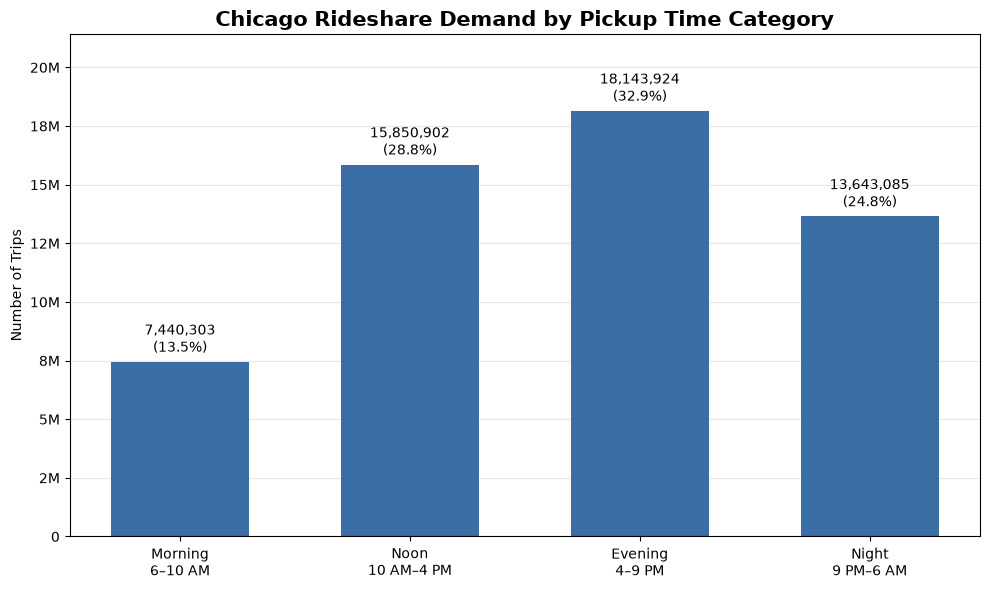

,Total_Trips,Percentage (%)
Pickup_Time_Category,,
Morning,7440303,13.51
Noon,15850902,28.78
Evening,18143924,32.94
Night,13643085,24.77


In [17]:
trip_counts = daily_counts.groupby("Pickup_Time_Category", observed=True)["Trips"].sum()

summary = pd.DataFrame({
    "Total_Trips": trip_counts,
    "Percentage (%)": (trip_counts / trip_counts.sum() * 100).round(2),
})

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar([f"{c}\n{CATEGORY_HOURS[c]}" for c in summary.index], summary["Total_Trips"], color="#3b6ea5", width=0.6)
ax.bar_label(bars, labels=[f"{t:,.0f}\n({p:.1f}%)" for t, p in zip(summary["Total_Trips"], summary["Percentage (%)"])], padding=4)
ax.set_ylim(0, summary["Total_Trips"].max() * 1.18)   # 18% headroom so the labels above the bars fit
ax.yaxis.set_major_formatter(EngFormatter(places=0, sep=""))
ax.set_ylabel("Number of Trips")
ax.set_title("Chicago Rideshare Demand by Pickup Time Category", fontsize=15, fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

display(summary)

### 7.2 Monthly demand by pickup time category
**What this does:** average trips **per day** in each month (so 28-day and 31-day months are comparable), plus each category's share of the month's trips.

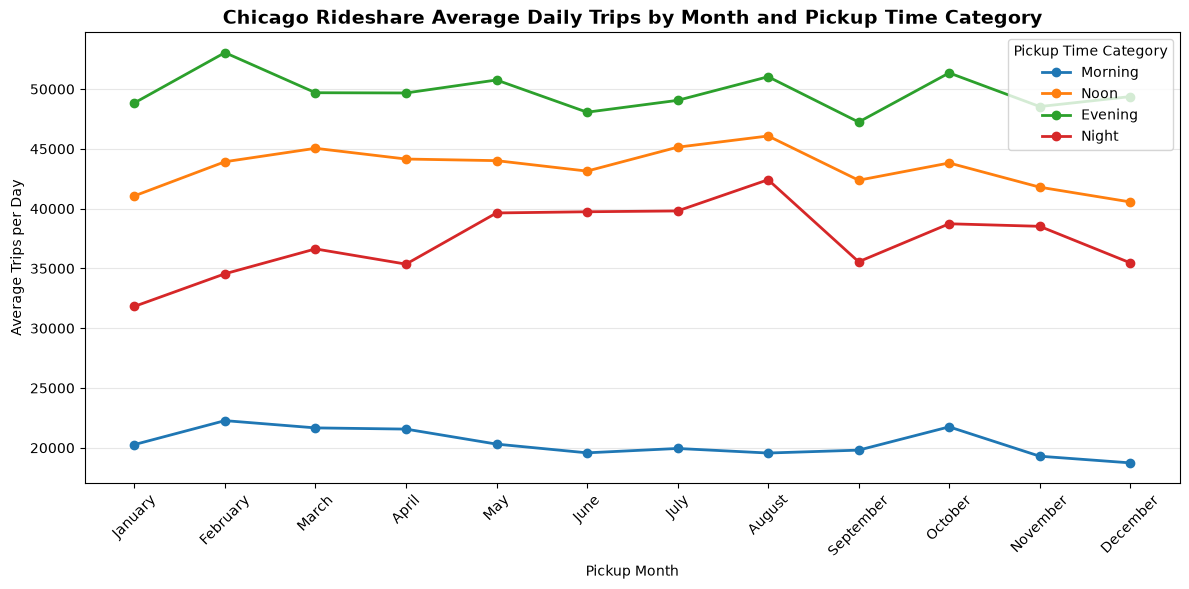

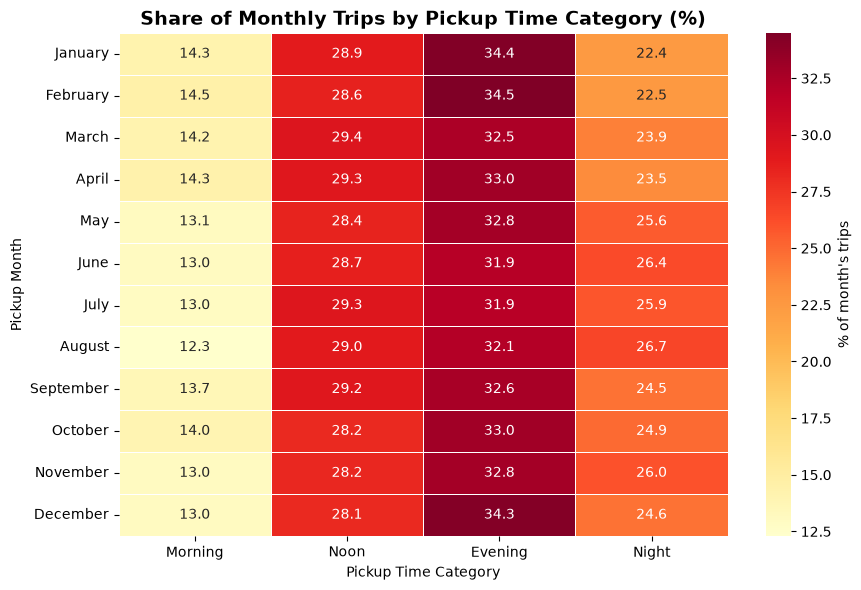

In [18]:
days_in_month = pd.Series([calendar.monthrange(YEAR, m)[1] for m in range(1, 13)], index=MONTH_NAMES)   # 28-31 days, from the calendar

monthly_demand = daily_counts.pivot_table(
    index="Pickup_Month", columns="Pickup_Time_Category", values="Trips",
    aggfunc="sum", observed=False, fill_value=0,
)
monthly_per_day = monthly_demand.div(days_in_month, axis=0)

ax = monthly_per_day.plot(kind="line", figsize=(12, 6), marker="o", linewidth=2)
ax.set_title("Chicago Rideshare Average Daily Trips by Month and Pickup Time Category", fontsize=14, fontweight="bold")
ax.set_xlabel("Pickup Month")
ax.set_ylabel("Average Trips per Day")
ax.legend(title="Pickup Time Category")
ax.grid(axis="y", alpha=0.3)
ax.set_xticks(range(12))
ax.set_xticklabels(MONTH_NAMES, rotation=45)
plt.tight_layout()
plt.show()

monthly_percentage = monthly_demand.div(monthly_demand.sum(axis=1), axis=0).mul(100)

plt.figure(figsize=(9, 6))
sns.heatmap(monthly_percentage, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5, cbar_kws={"label": "% of month's trips"})
plt.title("Share of Monthly Trips by Pickup Time Category (%)", fontsize=14, fontweight="bold")
plt.xlabel("Pickup Time Category")
plt.ylabel("Pickup Month")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.3 Pickup demand by community area (map)
**What this does:** colors Chicago's 77 community areas by total pickups. The boundary file is downloaded once and reused.

**Note:** colors use 7 **quantile bins** (`MAP_COLOR_BINS`; each color holds about the same number of areas, ~11 of 77). On a plain min-to-max scale a few very busy areas (the Loop, Near North Side, O'Hare) would make every other area look the same.

In [19]:
pickup_counts = df["pickup_community_area"].value_counts()      # NaN excluded automatically
demand_lookup = {int(area): int(n) for area, n in pickup_counts.items()}

if GEOJSON_CACHE.exists():
    chicago_geojson = json.loads(GEOJSON_CACHE.read_text())
else:
    response = requests.get(GEOJSON_URL, timeout=60)
    response.raise_for_status()
    chicago_geojson = response.json()
    GEOJSON_CACHE.parent.mkdir(parents=True, exist_ok=True)
    GEOJSON_CACHE.write_text(json.dumps(chicago_geojson))

for feature in chicago_geojson["features"]:
    props = feature["properties"]
    area_code = int(props["area_numbe"])
    feature["properties"] = {
        "Community_Code": area_code,
        "Community_Name": props["community"].title(),
        "Total_Pickups": demand_lookup.get(area_code, 0),
    }

values = [f["properties"]["Total_Pickups"] for f in chicago_geojson["features"]]
colormap = cm.linear.YlOrRd_09.scale(min(values), max(values)).to_step(n=MAP_COLOR_BINS, data=values, method="quantiles")
colormap.caption = "Total Rideshare Pickups (quantile bins)"

chicago_map = folium.Map(location=MAP_CENTER, zoom_start=MAP_ZOOM, tiles="OpenStreetMap")
folium.GeoJson(
    chicago_geojson,
    name="Pickup Demand",
    style_function=lambda feature: {
        "fillColor": colormap(feature["properties"]["Total_Pickups"]),
        "color": "black", "weight": 0.5, "fillOpacity": 0.75,
    },
    highlight_function=lambda feature: {"weight": 2, "color": "blue", "fillOpacity": 0.9},
    tooltip=folium.GeoJsonTooltip(
        fields=["Community_Name", "Community_Code", "Total_Pickups"],
        aliases=["Community Area:", "Community Code:", "Total Pickups:"],
        localize=True, sticky=True,
    ),
).add_to(chicago_map)
colormap.add_to(chicago_map)

MAP_PATH.parent.mkdir(parents=True, exist_ok=True)
chicago_map.save(str(MAP_PATH))
print(f"Map saved to {MAP_PATH}")
display(chicago_map)

Map saved to /Users/williamdang/Documents/Project/Output/rideshare_pickup_map.html


### 7.4 Weekly demand by pickup time category
**What this does:** total trips by weekday, split by time of day, with each segment's share of that day's trips.

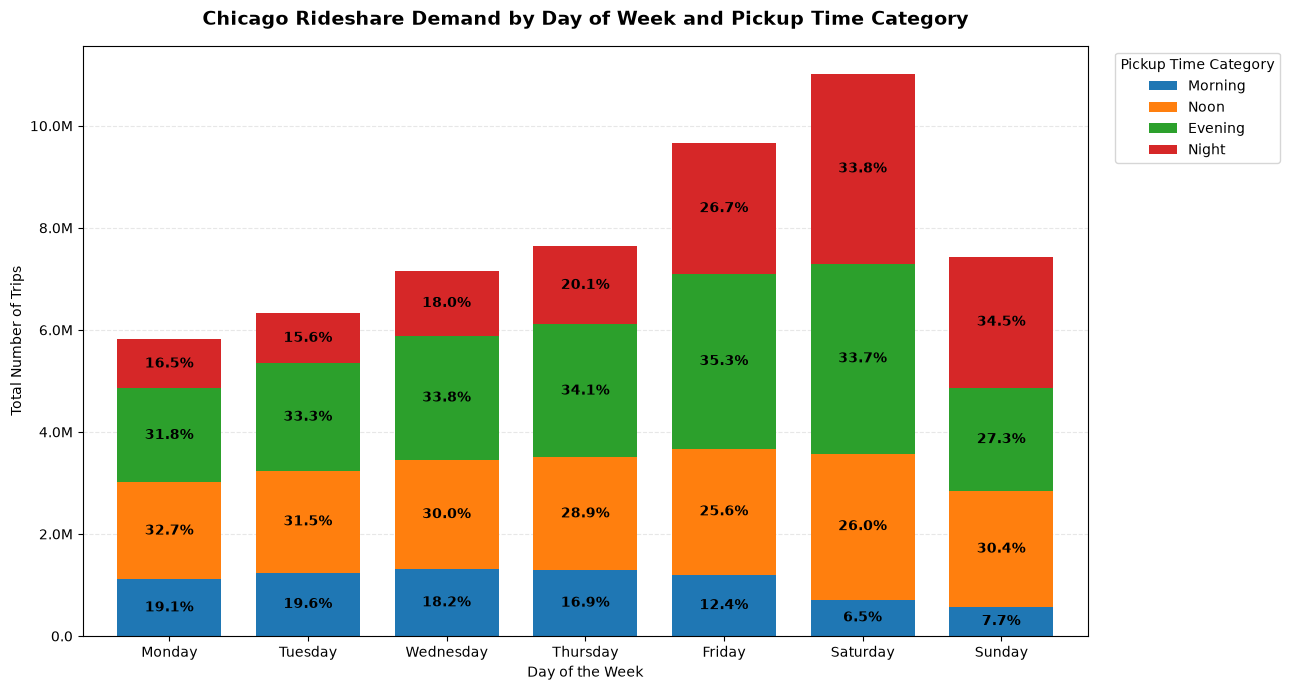

In [20]:
weekly_demand = daily_counts.pivot_table(
    index="Pickup_Day_of_Week", columns="Pickup_Time_Category", values="Trips",
    aggfunc="sum", observed=False, fill_value=0,
)
weekly_pct = weekly_demand.div(weekly_demand.sum(axis=1), axis=0).mul(100).fillna(0)

fig, ax = plt.subplots(figsize=(13, 7))
weekly_demand.plot(kind="bar", stacked=True, ax=ax, width=0.75)
for container, category in zip(ax.containers, weekly_demand.columns):
    labels = [f"{pct:.1f}%" if pct >= 3 else "" for pct in weekly_pct[category]]   # skip labels on segments under 3%: too thin to read
    ax.bar_label(container, labels=labels, label_type="center", fontsize=10, fontweight="bold")

ax.set_title("Chicago Rideshare Demand by Day of Week and Pickup Time Category", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Total Number of Trips")
ax.yaxis.set_major_formatter(EngFormatter(places=1, sep=""))
ax.legend(title="Pickup Time Category", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.5 Average daily pickups by month and weekday
**What this does:** one heatmap per time category, all on the same color scale, showing average pickups per day for each month × weekday combination.

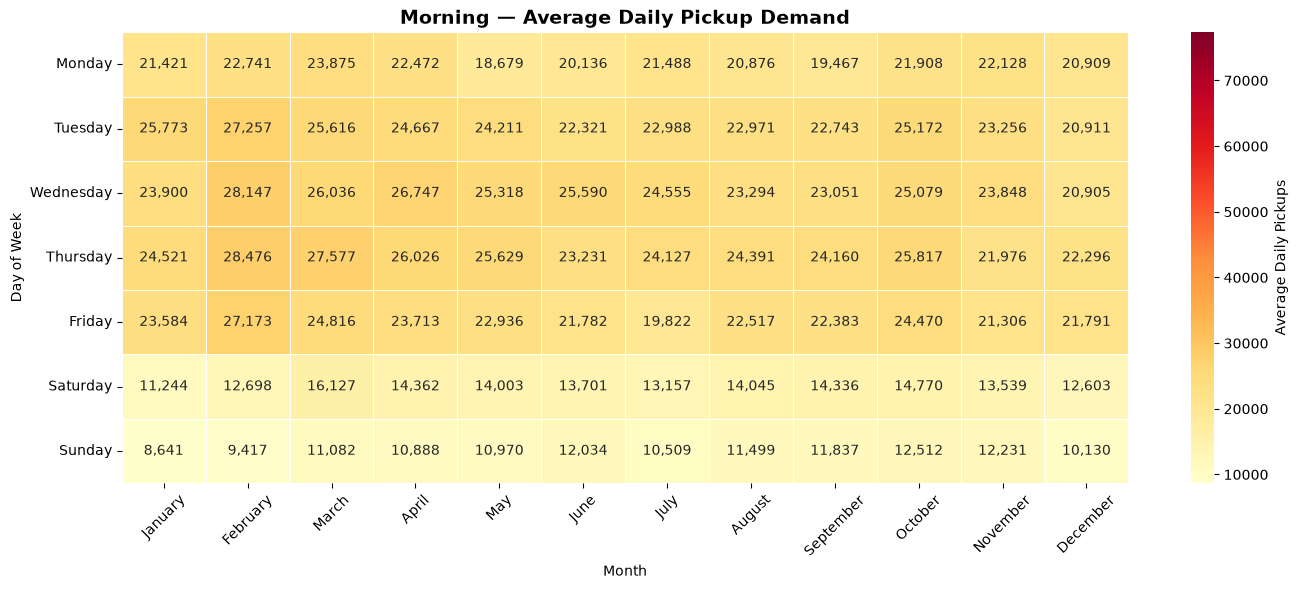

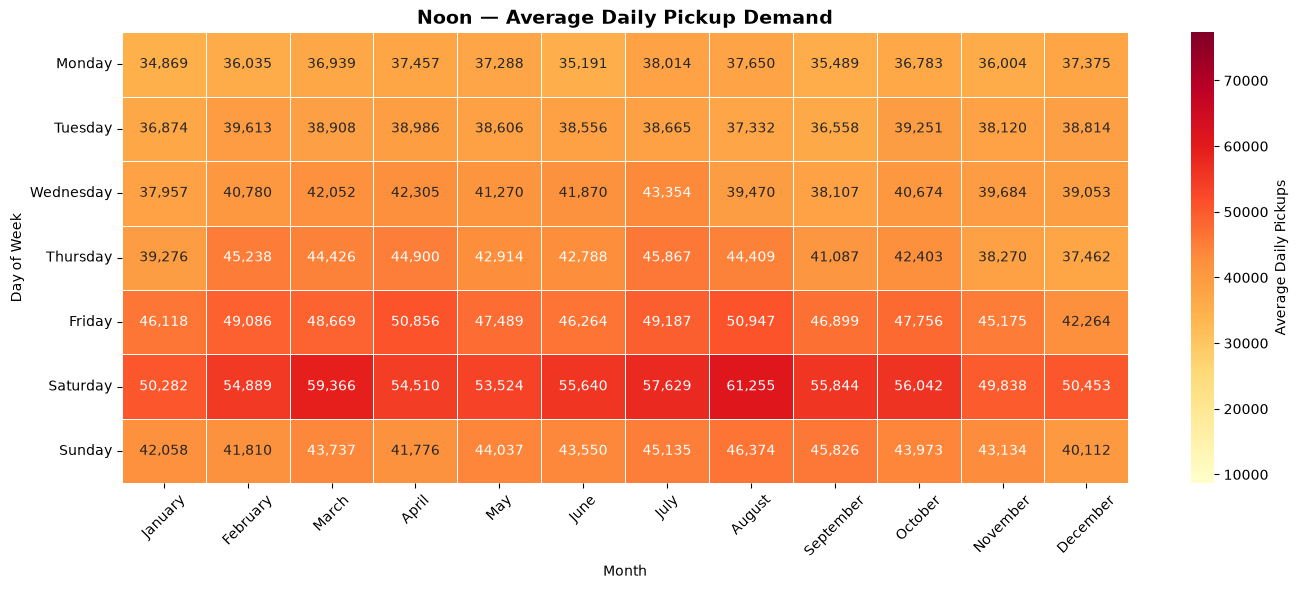

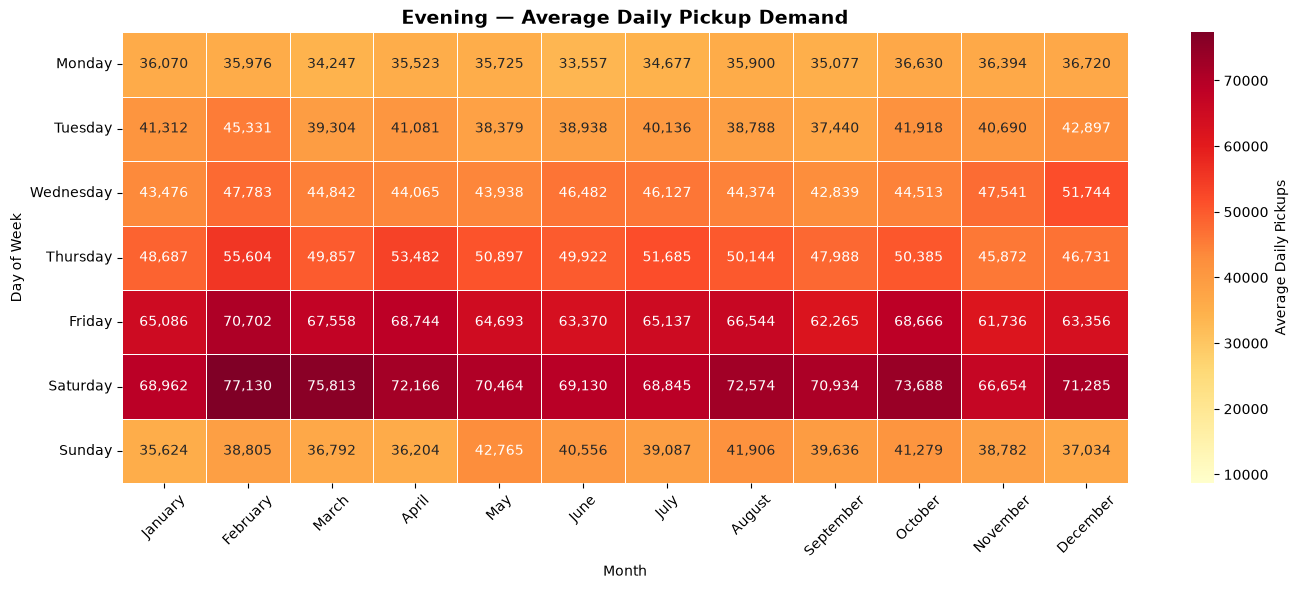

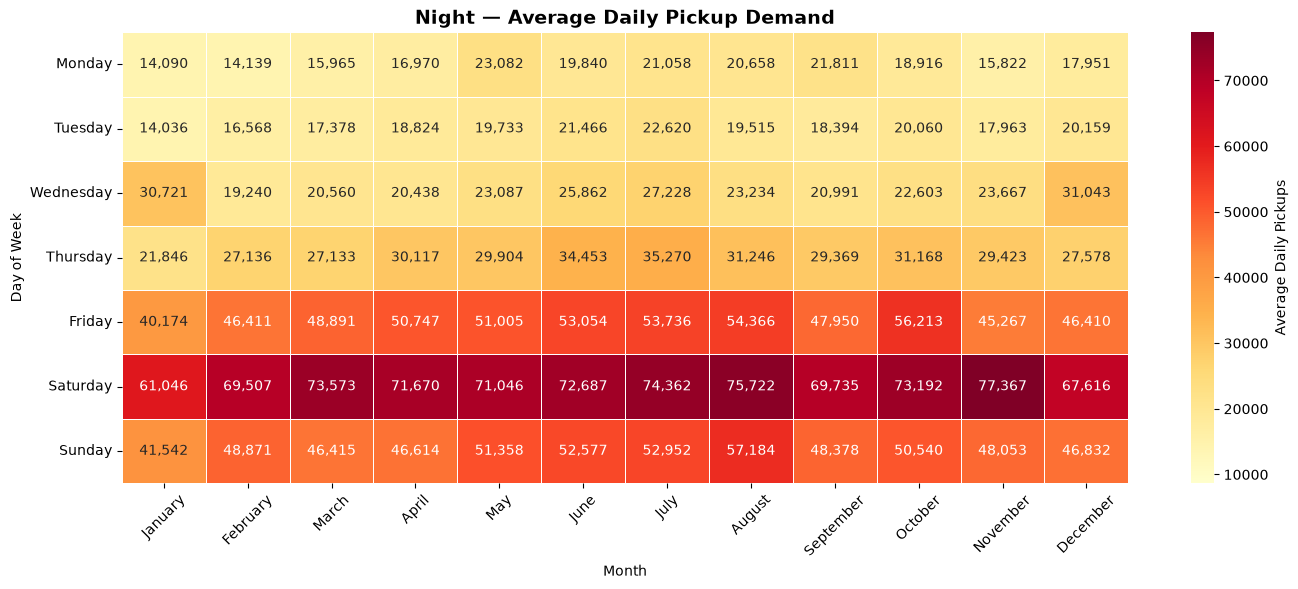

In [21]:
average_demand = (
    daily_counts
    .groupby(["Pickup_Month", "Pickup_Day_of_Week", "Pickup_Time_Category"], observed=True)["Trips"]
    .mean()
    .rename("Average_Daily_Pickups")
    .reset_index()
)
for col in ["Pickup_Month", "Pickup_Day_of_Week", "Pickup_Time_Category"]:
    average_demand[col] = average_demand[col].astype(str)

global_min = average_demand["Average_Daily_Pickups"].min()
global_max = average_demand["Average_Daily_Pickups"].max()

for category in TIME_CATEGORIES:
    heatmap_data = (
        average_demand[average_demand["Pickup_Time_Category"] == category]
        .pivot(index="Pickup_Day_of_Week", columns="Pickup_Month", values="Average_Daily_Pickups")
        .reindex(index=DAY_NAMES, columns=MONTH_NAMES)
    )
    plt.figure(figsize=(14, 6))
    sns.heatmap(heatmap_data, annot=True, fmt=",.0f", cmap="YlOrRd", vmin=global_min, vmax=global_max,
                linewidths=0.5, cbar_kws={"label": "Average Daily Pickups"})
    plt.title(f"{category} — Average Daily Pickup Demand", fontsize=14, fontweight="bold")
    plt.xlabel("Month")
    plt.ylabel("Day of Week")
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 8. Modeling: does local demand raise fares?
**Research question:** when local demand (pickups in one community area during one hour) rises above its normal level, does the fare of an otherwise comparable trip also rise above what the normal rate card predicts?

**Plan**
1. Build a regression sample (Section 8.1–8.3).
2. Measure **local demand** for every area × hour × day, compared with that area-hour's own normal (8.4–8.6).
3. Estimate the **rate card** – base + per-minute + per-mile – from normal-demand trips, and measure each fare as a % above or below it (8.7).
4. Fit two **identical** models, one without and one with demand, plus a "demand bucket" model to see the shape (8.8–8.9).
5. Compare **time-of-day categories** (8.10) and check that the settings do not drive the answer (8.11).
6. Measure how **rain and snow** change demand and price (8.12).

**What surge pricing looks like in practice:** in a study of Uber in Manhattan and San Francisco, most surges were 1.5× or less (average multiplier 1.07× in Manhattan, 1.36× in San Francisco; highest seen 2.8× and 4.1×), and surges were short – about 40% lasted only 5 minutes [2]. A short surge inside a 1-hour slot is averaged with normal minutes, so **this analysis will understate the size of individual surges**; it measures the average premium during busier-than-normal hours.

### 8.1 Prepare regression data
**What this does:** keeps trips with a valid fare, duration, distance, weather, calendar values and a pickup community area, and renames the weather columns for modeling.

In [22]:
model_cols = [
    "trip_start_timestamp", "Pickup_Date", "Pickup_Month", "Pickup_Day_of_Week", "Pickup_Time_Category",
    "pickup_community_area", "fare", "Trip_Minutes", "trip_miles", "PRCP (Inches)", "SNOW (Inches)",
]

valid = (
    df[model_cols].notna().all(axis=1)
    & (df["fare"] > 0)
    & (df["Trip_Minutes"] > 0)
    & (df["trip_miles"] >= 0)
)

reg_df = df.loc[valid, model_cols].rename(columns={"PRCP (Inches)": "Rain_Inches", "SNOW (Inches)": "Snow_Inches"})
del valid

print(f"Original cleaned dataset: {len(df):,}")
print(f"Regression population:    {len(reg_df):,}")
print(f"Population retained:      {len(reg_df) / len(df) * 100:.2f}%")

Original cleaned dataset: 55,078,214
Regression population:    54,543,324
Population retained:      99.03%


### 8.2 Weather indicators for stratified sampling
**What this does:** flags rainy and snowy trips so the sample keeps the same mix of weather conditions as the full data.

In [23]:
reg_df["Rain_Flag"] = (
    reg_df["Rain_Inches"] > 0
).astype("int8")

reg_df["Snow_Flag"] = (
    reg_df["Snow_Inches"] > 0
).astype("int8")


weather_distribution = pd.DataFrame({

    "Trips": [
        len(reg_df),
        reg_df["Rain_Flag"].sum(),
        reg_df["Snow_Flag"].sum()
    ],

    "Percentage": [
        100,
        reg_df["Rain_Flag"].mean() * 100,
        reg_df["Snow_Flag"].mean() * 100
    ]

}, index=[
    "All Trips",
    "Rain Trips",
    "Snow Trips"
])

display(
    weather_distribution.round(2)
)

,Trips,Percentage
All Trips,54543324,100.00
Rain Trips,16215900,29.73
Snow Trips,2933147,5.38


### 8.3 10% stratified sample and validation
**What this does:** draws 10% of trips (`SAMPLE_FRACTION`) while keeping the same mix of month, time category, rain and snow, then checks that the sample's averages match the full population.

**Note:** later, trips in quiet area-hours (below the minimum normal demand) are removed, so the final modeling sample is no longer *exactly* stratified. The time-category results are therefore also shown separately.

In [24]:
strata_cols = ["Pickup_Month", "Pickup_Time_Category", "Rain_Flag", "Snow_Flag"]

# Draw the same fraction from every month x time category x rain x snow group, so the sample keeps the
# population's mix. SAMPLE_FRACTION (10%) and RANDOM_SEED (fixed, for reproducibility) are explained in Section 1.
reg_sample = (
    reg_df
    .groupby(strata_cols, group_keys=False, observed=True)
    .sample(frac=SAMPLE_FRACTION, random_state=RANDOM_SEED)
)

print(f"Population Size: {len(reg_df):,}")
print(f"Sample Size:     {len(reg_sample):,}")
print(f"Sample Rate:     {len(reg_sample) / len(reg_df) * 100:.2f}%")

Population Size: 54,543,324
Sample Size:     5,454,331
Sample Rate:     10.00%


In [25]:
validation_cols = [
    "fare",
    "Trip_Minutes",
    "trip_miles",
    "Rain_Inches",
    "Snow_Inches"
]


sample_validation = pd.DataFrame({

    "Population_Mean":
        reg_df[validation_cols].mean(),

    "Sample_Mean":
        reg_sample[validation_cols].mean(),

    "Population_Median":
        reg_df[validation_cols].median(),

    "Sample_Median":
        reg_sample[validation_cols].median()
})


sample_validation["Mean_Difference_%"] = (
    (
        sample_validation["Sample_Mean"]
        - sample_validation["Population_Mean"]
    )
    / sample_validation["Population_Mean"]
    * 100
)


display(
    sample_validation.round(3)
)

,Population_Mean,Sample_Mean,Population_Median,Sample_Median,Mean_Difference_%
fare,17.558,17.562,12.5,12.5,0.022
Trip_Minutes,18.073,18.073,14.13,14.15,0.0
trip_miles,6.017,6.019,3.3,3.3,0.04
Rain_Inches,0.116,0.116,0.0,0.0,0.01
Snow_Inches,0.066,0.066,0.0,0.0,-0.015


### 8.4 Build local demand: pickup area × 1-hour slot
**What this does:** counts **all** pickups in the full dataset (not just the sample) for every one of the 77 areas × 365 days × 24 hours. The grid includes hours with **zero** trips, so quiet hours are not missing from the "normal" calculation.

**Purpose of the 1-hour slot:** it is the unit in which "how busy is it here, right now?" is measured. It must be local enough to capture a rush in one neighborhood, but large enough to contain enough pickups for the count to be meaningful. An hour does both; the cost is that a surge lasting only a few minutes is averaged with the normal minutes around it (see the note at the top of Section 8).

In [26]:
dates = full_year
N_DAYS = len(dates)
counts = np.zeros(N_AREAS * N_DAYS * N_SLOTS, dtype=np.int64)

for start in range(0, len(df), CHUNK_ROWS):          # CHUNK_ROWS: memory only, see Section 1
    chunk = df.iloc[start:start + CHUNK_ROWS]
    ts = chunk["trip_start_timestamp"]

    area = chunk["pickup_community_area"].to_numpy(dtype="float64", na_value=np.nan)
    day = (ts.dt.normalize() - dates[0]).dt.days.to_numpy(dtype="float64", na_value=np.nan)
    slot = ts.dt.hour.to_numpy(dtype="float64", na_value=np.nan)          # 1-hour slot = hour of day

    ok = (
        ~np.isnan(area) & ~np.isnan(day) & ~np.isnan(slot)
        & (area >= 1) & (area <= N_AREAS) & (day >= 0) & (day < N_DAYS)
    )
    flat = ((area[ok].astype(np.int64) - 1) * N_DAYS + day[ok].astype(np.int64)) * N_SLOTS + slot[ok].astype(np.int64)
    counts += np.bincount(flat, minlength=counts.size)

counts = counts.reshape(N_AREAS, N_DAYS, N_SLOTS)

print(f"Pickups in the grid: {counts.sum():,} of {len(df):,} trips (the rest have no pickup area)")
print(f"Grid cells: {counts.size:,} | cells with at least one pickup: {(counts > 0).mean() * 100:.1f}%")

Pickups in the grid: 54,773,371 of 55,078,214 trips (the rest have no pickup area)
Grid cells: 674,520 | cells with at least one pickup: 82.8%


### 8.5 Normal demand and the demand index
**What this does:** for every area × hour × day, "normal" demand is the average of the **same area, same weekday, same hour** over the ±4 surrounding weeks – **never including the day itself**. Then:

- `Demand_Index = actual pickups / normal pickups` (1.00 = normal, 1.20 = 20% busier than normal, 0.80 = 20% quieter)
- `Demand_Increase_10Pct = (Demand_Index − 1) × 10` – the model's demand variable, in steps of "10% above normal"

Example: an area that normally has 100 pickups at 6 PM on Fridays and has 130 this Friday has an index of 1.30, which is 3 steps of +10%.

**Purpose of the "normal demand" benchmark:** a raw count cannot tell you whether an hour is busy. 300 pickups is a normal Friday evening downtown but an extraordinary one in a quiet neighborhood. The benchmark answers "busy **compared with what is usual for this place and time**":
- **Same area:** downtown is compared with downtown, never with a residential neighborhood.
- **Same weekday and hour:** Friday 6 PM is compared with other Fridays at 6 PM, because demand follows a weekly rhythm (commutes, weekends, nightlife).
- **±4 surrounding weeks** (`BENCHMARK_WEEKS`): the 8 nearest comparable days. That is enough days for a stable average, and close enough in time to follow the seasons (a July Friday is compared with June–August Fridays, not with January).
- **The day itself is excluded:** if today were part of its own average, a busy day would raise its own benchmark and look less busy than it really was.

One limitation: holidays (e.g. July 4) are compared with ordinary days, so they will look unusually busy or quiet.

**Purpose of the minimum normal demand:** pickup counts bounce around by chance. A count with a normal level of *n* typically moves by about 1/√*n*, so an area that normally has 2 pickups can show 4 by pure luck and look "100% busier". Requiring at least 12 normal pickups per hour (`MIN_EXPECTED`, calculated as 1 / 0.30² from `MAX_RELATIVE_NOISE`) limits that chance movement to about 30%, so the demand index reflects real changes. The floor only removes quiet area-hours; busy downtown hours are far above it and are never affected.

**Purpose of the cap:** a few one-off events (a parade, a stadium letting out) can push the index to 5× or more. In a straight-line fit those few hours would pull the whole line toward them. Capping at the 99th percentile (`DEMAND_INDEX_CAP_PCTL`) keeps them in the analysis as "very busy" without letting them dominate; trimming at the 1st/99th percentile is a common convention in empirical research. This is **not** the same as the 5% significance level, which is about how sure we need to be before calling a result real.

Minimum normal demand: 12 pickups per hour | cap at the 99th percentile = 2.11x normal
Area-hours used: 339,240 | share of all pickups in them: 97.5%


count    339240.000
mean          0.990
std           0.333
min           0.003
5%            0.464
25%           0.795
50%           0.976
75%           1.162
90%           1.390
95%           1.569
max           2.111
Name: Demand_Index, dtype: float64

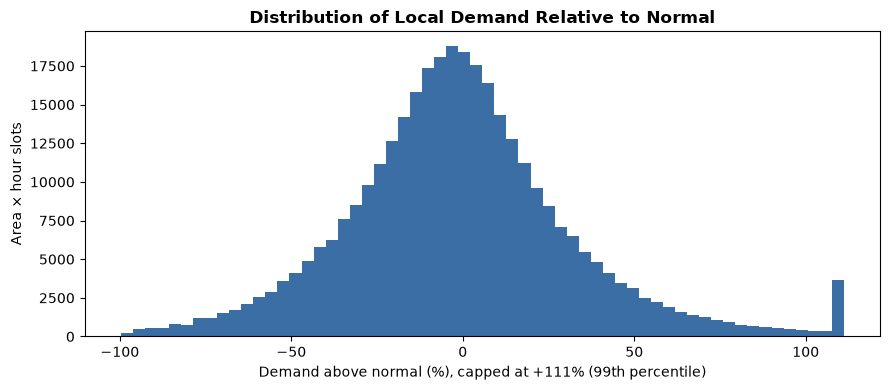

In [27]:
exp_sum = np.zeros(counts.shape, dtype=np.float64)
exp_n = np.zeros(counts.shape, dtype=np.float64)

for k in range(1, BENCHMARK_WEEKS + 1):
    s = 7 * k                                   # 7 days = one week, so day +-7k is the same weekday k weeks away
    exp_sum[:, s:, :] += counts[:, :-s, :]
    exp_n[:, s:, :] += 1
    exp_sum[:, :-s, :] += counts[:, s:, :]
    exp_n[:, :-s, :] += 1

expected = exp_sum / exp_n                      # never includes the day itself


def make_local_demand(min_expected, cap_pctl):
    """Demand index for every area x day x hour that had pickups and a normal level >= min_expected."""
    keep = (counts > 0) & (expected >= min_expected)
    a_idx, d_idx, s_idx = np.nonzero(keep)
    if len(a_idx) == 0:
        raise ValueError(
            f"No area x hour slots reach a normal demand of {min_expected} pickups. "
            "Raise MAX_RELATIVE_NOISE in Section 1 (it lowers the minimum), or check that the data covers the full year."
        )

    ld = pd.DataFrame({
        "pickup_community_area": (a_idx + 1).astype("int32"),
        "date_id": d_idx.astype("int32"),
        "Time_Slot": s_idx.astype("int32"),
        "Actual_Demand": counts[keep],
        "Expected_Demand": expected[keep],
    })
    ratio = ld["Actual_Demand"] / ld["Expected_Demand"]
    cap = float(np.percentile(ratio, cap_pctl))                  # cap set from the data
    ld["Demand_Index"] = ratio.clip(upper=cap)
    ld["Demand_Above_Normal_Pct"] = (ld["Demand_Index"] - 1) * 100
    ld["Demand_Increase_10Pct"] = ld["Demand_Above_Normal_Pct"] / 10
    share = counts[keep].sum() / counts.sum() * 100
    return ld, cap, share


local_demand, cap_value, share_trips = make_local_demand(MIN_EXPECTED, DEMAND_INDEX_CAP_PCTL)

print(f"Minimum normal demand: {MIN_EXPECTED} pickups per hour | cap at the {DEMAND_INDEX_CAP_PCTL}th percentile = {cap_value:.2f}x normal")
print(f"Area-hours used: {len(local_demand):,} | share of all pickups in them: {share_trips:.1f}%")
display(local_demand["Demand_Index"].describe(percentiles=[.05, .25, .5, .75, .9, .95]).round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(local_demand["Demand_Above_Normal_Pct"], bins=60, color="#3b6ea5")
ax.set_xlabel(f"Demand above normal (%), capped at +{(cap_value - 1) * 100:.0f}% ({DEMAND_INDEX_CAP_PCTL}th percentile)")
ax.set_ylabel("Area × hour slots")
ax.set_title("Distribution of Local Demand Relative to Normal", fontweight="bold")
plt.tight_layout()
plt.show()

### 8.6 Attach local demand to the sample and sort into demand buckets
**What this does:** gives each sampled trip the demand index of **its own pickup area and hour**, then sorts trips into buckets.

**Purpose of the buckets:** a single straight-line number assumes fares rise smoothly with demand. Surge pricing often switches on only past a threshold, so the buckets let the data show its own shape. Every bucket is compared with the normal bucket (0.9–1.1). If an area normally has 100 pickups in an hour:

| Bucket | Pickups that hour | Meaning |
|---|---|---|
| < 0.8 | under 80 | quiet |
| 0.8–0.9 | 80–89 | a bit quiet |
| **0.9–1.1** | **90–109** | **normal (reference)** |
| 1.1–1.2 | 110–119 | a bit busy |
| 1.2–1.5 | 120–149 | busy |
| > 1.5 | 150+ | very busy |

In quiet areas near the 12-pickup floor, chance alone moves the count by up to about ±30%, so some trips land in "busy" by luck. In busy areas (100+ pickups) chance moves it only about ±10%, so the buckets are most reliable there.

In [28]:
reg_sample["pickup_community_area"] = reg_sample["pickup_community_area"].astype("int32")
reg_sample["date_id"] = (reg_sample["Pickup_Date"] - dates[0]).dt.days.astype("int32")
reg_sample["Time_Slot"] = reg_sample["trip_start_timestamp"].dt.hour.astype("int32")      # 1-hour slot
reg_sample["month_id"] = reg_sample["Pickup_Month"].cat.codes.astype("int8")
reg_sample["dow_id"] = reg_sample["Pickup_Day_of_Week"].cat.codes.astype("int8")

reg_sample_base = reg_sample                    # every sampled trip, before a demand index is attached

n_before = len(reg_sample)
reg_sample = reg_sample_base.merge(
    local_demand, on=["pickup_community_area", "date_id", "Time_Slot"], how="left",
).dropna(subset=["Demand_Increase_10Pct"])

print(f"Sampled trips: {n_before:,} | with a usable local demand index: {len(reg_sample):,} "
      f"({len(reg_sample) / n_before * 100:.1f}%)")

reg_sample["Demand_Bin"] = pd.cut(reg_sample["Demand_Index"], DEMAND_BIN_EDGES, labels=DEMAND_BIN_LABELS, right=False)
BIN_VARS = {"<0.8": "bin_lt08", "0.8-0.9": "bin_08_09", "1.1-1.2": "bin_11_12", "1.2-1.5": "bin_12_15", ">1.5": "bin_gt15"}
for label, var in BIN_VARS.items():
    reg_sample[var] = (reg_sample["Demand_Bin"] == label).astype("int8")

display(reg_sample["Demand_Bin"].value_counts(sort=False).to_frame("Sampled_Trips"))

Sampled trips: 5,454,331 | with a usable local demand index: 5,318,856 (97.5%)


,Sampled_Trips
Demand_Bin,
<0.8,510011
0.8-0.9,656225
0.9-1.1 (normal),2421344
1.1-1.2,717017
1.2-1.5,723514
>1.5,290745


### 8.7 Rate card: the normal price recipe
**What this does:** rideshare fares are built from a recipe:

> **Fare = base fare + (rate per minute × minutes) + (rate per mile × miles)**

The recipe is estimated in dollars from **normal-demand trips only** (bucket 0.9–1.1), so busy hours cannot inflate the rates. Every trip then gets a "rate-card fare", and the models measure **how far the actual fare is above or below it, in %**.

**Purpose of the rate card benchmark:** to judge whether a fare is "high", it has to be compared with what that exact trip normally costs. A 20-minute, 8-mile ride and a 5-minute, 1-mile ride cannot be compared directly, but each can be compared with its own rate-card price. Estimating the card from normal-demand trips only keeps busy hours from inflating the "normal" price.

**Why measure in %:** surge pricing multiplies the whole price. A ×1.3 surge adds \$3 to a \$10 ride and \$12 to a \$40 ride: different in dollars, the same 30%. A dollar version is reported as a cross-check.

**Sanity check against published rates:** a third-party breakdown of Chicago UberX pricing lists a \$1.87 base fare plus a \$1.85 booking fee, \$0.30 per minute and \$0.85 per mile, with a \$4.98 minimum fare [3]. The estimate below should be in that neighborhood. Large differences would point to a data issue, a different platform mix (the data does not say Uber vs. Lyft), or fees handled differently.

**Things that blur the rate card:**
- The data rounds every fare to the nearest \$2.50 [1]. Single trips are imprecise; averages over millions of trips are not.
- Short trips are held up by the minimum fare, so they sit above the straight recipe line.
- City surcharges – \$1.13 ground transportation surcharge, \$1.50 downtown congestion-zone surcharge (6 AM–10 PM), \$5 at the airports, Navy Pier and McCormick Place [4][5] – probably sit in `additional_charges` rather than `fare`; the data description does not say.

In [29]:
RHS_CONTROLS = "Trip_Minutes + trip_miles + Rain_Inches + Snow_Inches"
KEY = "Demand_Increase_10Pct"
NUMERIC = ["fare", "log_fare", "Trip_Minutes", "trip_miles", "Rain_Inches", "Snow_Inches", KEY, "Demand_Index"] + list(BIN_VARS.values())

reg_sample["log_fare"] = 0.0                    # filled below with the % gap to the rate card
reg_model = reg_sample[
    ["Pickup_Time_Category", "Demand_Bin", "month_id", "dow_id", "Time_Slot", "pickup_community_area", "date_id"] + NUMERIC
].copy()
reg_model[NUMERIC] = reg_model[NUMERIC].astype("float64")

# Estimate the rate card on normal-demand trips
normal = reg_model["Demand_Bin"] == NORMAL_BIN
rc = pf.feols("fare ~ Trip_Minutes + trip_miles", data=reg_model[normal]).coef()


def rate_card_fare(frame):
    # clip(lower=1.0): a 1-dollar floor stops a tiny or odd trip from getting a near-zero or negative rate-card
    # price (which would make the % gap explode); real fares never go that low (minimum fare ~5 dollars).
    return (rc["Intercept"] + rc["Trip_Minutes"] * frame["Trip_Minutes"] + rc["trip_miles"] * frame["trip_miles"]).clip(lower=1.0)


reg_model["rate_card_fare"] = rate_card_fare(reg_model)
reg_model["log_fare"] = np.log(reg_model["fare"] / reg_model["rate_card_fare"])                          # % gap (log points)
reg_sample_base["log_fare"] = np.log(reg_sample_base["fare"] / rate_card_fare(reg_sample_base))         # same, for 8.11

rate_check = pd.DataFrame({
    "Estimated from data": [rc["Intercept"], rc["Trip_Minutes"], rc["trip_miles"]],
    "Published UberX (third-party, 2024) [3]": list(RESEARCH_RATE_CARD.values()),
}, index=list(RESEARCH_RATE_CARD.keys())).round(3)

print(f"Estimated rate card: base ${rc['Intercept']:.2f} + ${rc['Trip_Minutes']:.3f}/min + ${rc['trip_miles']:.3f}/mile "
      f"(from {int(normal.sum()):,} normal-demand trips)")
display(rate_check)
# The 4.98 dollar minimum fare appears in the data as 5.00, because fares are rounded to the nearest 2.50
min_fare_in_data = round(RESEARCH_MIN_FARE / FARE_ROUNDING) * FARE_ROUNDING
print(f"Trips at or below a ${min_fare_in_data:.2f} fare (minimum-fare zone): {(reg_model['fare'] <= min_fare_in_data).mean() * 100:.1f}%")

Estimated rate card: base $3.66 + $0.418/min + $1.052/mile (from 2,421,344 normal-demand trips)


,Estimated from data,"Published UberX (third-party, 2024) [3]"
Base + booking fee,3.656,3.72
Per minute,0.418,0.30
Per mile,1.052,0.85


Trips at or below a $5.00 fare (minimum-fare zone): 10.5%


### 8.8 Fare models: control vs. surge (identical except for demand)
**What this does:**
- **Model A (control):** fare gap to the rate card ~ minutes + miles + rain + snow + adjustments
- **Model B (surge):** Model A **+ demand** – the only difference, so any improvement comes from demand alone
- **Model C (shape):** Model A + demand buckets, to see whether fares rise gradually or only at high demand

Each runs for all trips together and for each time-of-day category, in % (main) and in dollars (cross-check).

**Purpose of the adjustments:** fares differ by month, weekday, hour and area for reasons unrelated to demand surges (seasonal promotions, airport fees, longer downtown blocks). The adjustments remove those regular differences so the demand effect is measured on otherwise comparable trips. They are separate fixed effects for month, weekday, hour and pickup area. Think of them as stickers that add to the price: a "downtown" sticker and a "6 PM" sticker are added together for a downtown ride at 6 PM. If downtown at 6 PM is special beyond that sum, the model does not see it; because the demand index already compares each area-hour with its own normal, this mostly adds noise rather than bias.

**Purpose of clustering:** trips on the same day (weather, events) or in the same area (local pricing) are not independent, so the error bars are clustered by **date and pickup area** [6], computed with `pyfixest` [7]. If two-way clustering is numerically unusable in a small group, that model falls back to clustering by date only, and the notebook prints how often.

**Purpose of the 95% rule:** with millions of trips, random noise can still produce small non-zero estimates. A result is called "higher" or "lower" only if the 95% confidence interval excludes zero, the standard 5% significance level.

In [ ]:
FIXED_EFFECTS = "month_id + dow_id + Time_Slot + pickup_community_area"
VCOV = {"CRV1": "date_id + pickup_community_area"}
fallbacks = []


def fit_fe(formula, data):
    """Fit with two-way clustered SEs; if the two-way covariance is unusable (NaN SEs), refit clustering by date only."""
    m = pf.feols(formula, data=data, vcov=VCOV)
    if np.isnan(m.se().to_numpy()).any():
        fallbacks.append(formula.split("|")[0].strip()[:60])
        m = pf.feols(formula, data=data, vcov={"CRV1": "date_id"})
    return m


groups = {"All trips": reg_model}
for cat in TIME_CATEGORIES:
    groups[cat] = reg_model[reg_model["Pickup_Time_Category"] == cat]

SPEC_PCT, SPEC_USD = "% vs rate card", "fare ($)"
results, bin_results, premium_by_bin = [], [], None

for spec, y in [(SPEC_PCT, "log_fare"), (SPEC_USD, "fare")]:
    for group, data in groups.items():
        a = fit_fe(f"{y} ~ {RHS_CONTROLS} | {FIXED_EFFECTS}", data)
        b = fit_fe(f"{y} ~ {RHS_CONTROLS} + {KEY} | {FIXED_EFFECTS}", data)

        ci = b.confint().loc[KEY]
        results.append({
            "Spec": spec, "Group": group, "Trips": int(b._N),
            "Coef_per_10pct": float(b.coef()[KEY]), "Std_Error": float(b.se()[KEY]), "P_Value": float(b.pvalue()[KEY]),
            "CI_Low": float(ci.iloc[0]), "CI_High": float(ci.iloc[1]),
            "R2_Control": float(a._r2), "R2_Surge": float(b._r2),
        })

        if y == "log_fare":
            c = fit_fe(f"{y} ~ {RHS_CONTROLS} + {' + '.join(BIN_VARS.values())} | {FIXED_EFFECTS}", data)
            cc, cci = c.coef(), c.confint()
            for label, var in BIN_VARS.items():
                bin_results.append({
                    "Group": group, "Demand_Bin": label,
                    "Fare_vs_Normal_%": (np.exp(cc[var]) - 1) * 100,
                    "CI_Low_%": (np.exp(cci.loc[var].iloc[0]) - 1) * 100,
                    "CI_High_%": (np.exp(cci.loc[var].iloc[1]) - 1) * 100,
                })
            if group == "All trips":
                resid = a.resid()
                assert len(resid) == len(data)
                premium = pd.DataFrame({"Demand_Bin": data["Demand_Bin"].reset_index(drop=True),
                                        "Fare_Premium_%": (np.exp(resid) - 1) * 100})
                premium_by_bin = (premium.groupby("Demand_Bin", observed=True)["Fare_Premium_%"]
                                  .agg(Trips="size", Mean_Premium_Pct="mean", Median_Premium_Pct="median"))
        del a, b

results = pd.DataFrame(results)
results["R2_Gain"] = results["R2_Surge"] - results["R2_Control"]
bin_results = pd.DataFrame(bin_results)
print("Models fitted:", len(results) * 2 + len(bin_results) // len(BIN_VARS))
if fallbacks:
    print(f"Note: {len(fallbacks)} model(s) used date-only clustering because two-way clustering was not usable.")

### 8.9 Results
**How to read the table:** `Effect` is the change in fare for every 10% that local demand is above normal – in % for the main spec and in dollars for the cross-check – with its 95% confidence interval.

**Why R² looks small in the % spec:** the rate card already explains most of the fare; the models only explain the leftover gap, so a small R² is expected. Judge demand by the size and confidence interval of its effect, not by R².

In [ ]:
pct_rows = results["Spec"] == SPEC_PCT
table = results.copy()
table["Effect"] = np.where(pct_rows, (np.exp(table["Coef_per_10pct"]) - 1) * 100, table["Coef_per_10pct"])
table["Effect_CI_Low"] = np.where(pct_rows, (np.exp(table["CI_Low"]) - 1) * 100, table["CI_Low"])
table["Effect_CI_High"] = np.where(pct_rows, (np.exp(table["CI_High"]) - 1) * 100, table["CI_High"])
table["Unit"] = np.where(pct_rows, "% of fare", "$")

display(
    table[["Spec", "Group", "Trips", "Effect", "Effect_CI_Low", "Effect_CI_High", "Unit", "P_Value", "R2_Control", "R2_Surge", "R2_Gain"]]
    .round({"Effect": 3, "Effect_CI_Low": 3, "Effect_CI_High": 3, "P_Value": 4, "R2_Control": 4, "R2_Surge": 4, "R2_Gain": 5})
)

# Shape: fare vs. a comparable normal-demand trip, by demand bucket (all trips)
order = ["<0.8", "0.8-0.9", "1.1-1.2", "1.2-1.5", ">1.5"]
plot_data = bin_results[bin_results["Group"] == "All trips"].set_index("Demand_Bin").loc[order]

fig, ax = plt.subplots(figsize=(9, 5))
vals = plot_data["Fare_vs_Normal_%"]
ax.bar(order, vals, yerr=[vals - plot_data["CI_Low_%"], plot_data["CI_High_%"] - vals], capsize=5, color="#3b6ea5")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Local demand relative to normal (0.9-1.1 = reference)")
ax.set_ylabel("Fare vs. comparable normal-demand trip (%)")
ax.set_title("Fare by Local Demand Level (all trips, 95% CI)", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("Average fare gap to the control model's expected fare, by demand bucket (all trips):")
display(premium_by_bin.round(3))

### 8.10 Time-of-day categories: demand vs. surge response
**What this does:** compares the four pickup time categories on two questions:
1. **How much demand is there, and how often is it above normal?** – total trips, trips per hour (windows differ in length), and the share of trips taken in busy (≥ 1.2×) and very busy (≥ 1.5×) hours.
2. **How strongly do fares respond?** – the % fare change per +10% demand, the fare change at a busy moment for that category, and the fare in very busy hours vs. normal hours.

A formal test then checks whether each category's response **differs** from the busiest category's (one model with a separate demand slope per category).

**Note:** high *volume* and strong *surge response* are different things. The demand index compares each area-hour with its own normal, so Evening can carry the most trips while Night reacts more strongly to an unusual rush – for example because fewer drivers are on the road at night (driver supply is not in the data).

In [ ]:
pct_tbl = table[table["Spec"] == SPEC_PCT].set_index("Group")
usd_tbl = table[table["Spec"] == SPEC_USD].set_index("Group")
bins_tbl = bin_results.set_index(["Group", "Demand_Bin"])

profile_rows = []
for cat in TIME_CATEGORIES:
    sub = reg_model[reg_model["Pickup_Time_Category"] == cat]
    coef = pct_tbl.loc[cat, "Coef_per_10pct"]
    busy_level = sub[KEY].quantile(HIGH_DEMAND_PCTL / 100)              # this category's busy moment
    total = int(summary.loc[cat, "Total_Trips"])
    profile_rows.append({
        "Category": cat,
        "Hours": CATEGORY_HOURS[cat],
        "Trips_2025": total,
        "Share_of_Trips_%": float(summary.loc[cat, "Percentage (%)"]),
        "Trips_per_Hour": total / (N_DAYS * HOURS_PER_CATEGORY[cat]),
        "Avg_Fare": sub["fare"].mean(),
        "Busy_Hours_Share_%": (sub["Demand_Index"] >= BUSY_INDEX).mean() * 100,
        "Very_Busy_Share_%": (sub["Demand_Index"] >= VERY_BUSY_INDEX).mean() * 100,
        "Fare_%_per_10pct": pct_tbl.loc[cat, "Effect"],
        "CI_Low_%": pct_tbl.loc[cat, "Effect_CI_Low"],
        "CI_High_%": pct_tbl.loc[cat, "Effect_CI_High"],
        "Dollars_per_10pct": usd_tbl.loc[cat, "Effect"],
        "Busy_Moment_Above_Normal_%": busy_level * 10,
        "Fare_%_at_Busy_Moment": (np.exp(coef * busy_level) - 1) * 100,
        "Very_Busy_Fare_vs_Normal_%": bins_tbl.loc[(cat, ">1.5"), "Fare_vs_Normal_%"],
        "Very_Busy_CI_Low_%": bins_tbl.loc[(cat, ">1.5"), "CI_Low_%"],
        "Very_Busy_CI_High_%": bins_tbl.loc[(cat, ">1.5"), "CI_High_%"],
    })
cat_profile = pd.DataFrame(profile_rows).set_index("Category")

# Does each category's demand slope differ from the busiest category's?
ref_cat = cat_profile["Trips_per_Hour"].idxmax()
others = [c for c in TIME_CATEGORIES if c != ref_cat]
for c in others:
    reg_model[f"{KEY}_x_{c}"] = reg_model[KEY] * (reg_model["Pickup_Time_Category"] == c)
inter = fit_fe(f"log_fare ~ {RHS_CONTROLS} + {KEY} + {' + '.join(f'{KEY}_x_{c}' for c in others)} | {FIXED_EFFECTS}", reg_model)
ic, ici, ip = inter.coef(), inter.confint(), inter.pvalue()
diff_rows = [{
    "Category": c, "Compared_with": ref_cat,
    "Difference_pp_per_10pct": ic[f"{KEY}_x_{c}"] * 100,          # x100: log points -> percentage points
    "CI_Low_pp": ici.loc[f"{KEY}_x_{c}"].iloc[0] * 100,
    "CI_High_pp": ici.loc[f"{KEY}_x_{c}"].iloc[1] * 100,
    "P_Value": float(ip[f"{KEY}_x_{c}"]),
} for c in others]
cat_diff = pd.DataFrame(diff_rows).set_index("Category")

display(cat_profile.round(2))
print(f"Difference in surge response vs. {ref_cat} (percentage points of fare per +10% demand):")
display(cat_diff.round(4))

# Chart: demand intensity (left) and fare response by demand bucket (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

bars = ax1.bar([f"{c}\n{CATEGORY_HOURS[c]}" for c in cat_profile.index], cat_profile["Trips_per_Hour"], color="#3b6ea5")
ax1.bar_label(bars, labels=[f"{v:,.0f}/h\n{s:.0f}% busy" for v, s in zip(cat_profile["Trips_per_Hour"], cat_profile["Busy_Hours_Share_%"])], padding=3)
ax1.set_ylim(0, cat_profile["Trips_per_Hour"].max() * 1.25)   # 25% headroom for the two-line labels
ax1.set_ylabel("Average trips per hour (citywide)")
ax1.set_title(f"Demand: trips per hour and share of trips in busy hours (≥{BUSY_INDEX}× normal)", fontweight="bold", fontsize=11)
ax1.grid(axis="y", alpha=0.3)
ax1.set_axisbelow(True)

bucket_order = ["<0.8", "0.8-0.9", NORMAL_BIN, "1.1-1.2", "1.2-1.5", ">1.5"]
x = np.arange(len(bucket_order))
for i, cat in enumerate(TIME_CATEGORIES):
    vals = [0.0 if b == NORMAL_BIN else bins_tbl.loc[(cat, b), "Fare_vs_Normal_%"] for b in bucket_order]
    lo = [0.0 if b == NORMAL_BIN else bins_tbl.loc[(cat, b), "CI_Low_%"] for b in bucket_order]
    hi = [0.0 if b == NORMAL_BIN else bins_tbl.loc[(cat, b), "CI_High_%"] for b in bucket_order]
    ax2.errorbar(x + (i - 1.5) * 0.08, vals,                 # small sideways offset so the 4 lines don't overlap yerr=[np.subtract(vals, lo), np.subtract(hi, vals)],
                 marker="o", capsize=3, linewidth=1.8, label=cat)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(x)
ax2.set_xticklabels([b.replace(" (normal)", "\n(normal)") for b in bucket_order])
ax2.set_xlabel("Local demand relative to normal")
ax2.set_ylabel("Fare vs. normal-demand trip (%)")
ax2.set_title("Surge response: fare by demand bucket and time of day (95% CI)", fontweight="bold", fontsize=11)
ax2.legend(title="Time of day")
ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 8.11 Sensitivity: do the settings drive the answer?
**What this does:** re-runs the all-trips model with different settings – minimum normal pickups of 5, 12, 20 and 50 per hour, and caps at the 95th, 99th and 100th (no cap) percentile.

**Purpose of the sensitivity check:** the minimum and the cap are reasonable choices, but other reasonable values exist. Re-running with several of them is like baking the same cake at slightly different oven temperatures – if every run gives a similar answer, the result is solid; if the answer flips sign or loses significance, the settings are driving it. Raising the minimum to 50 also shows the result for busy area-hours only. The rate card from 8.7 is held fixed.

In [ ]:
KEYS = ["pickup_community_area", "date_id", "Time_Slot"]
FLOAT_COLS = ["log_fare", "Trip_Minutes", "trip_miles", "Rain_Inches", "Snow_Inches", KEY]
FE_COLS = ["month_id", "dow_id", "Time_Slot", "pickup_community_area", "date_id"]

sens_rows = []
for min_exp in SENSITIVITY_MIN_EXPECTED:
    for pctl in SENSITIVITY_CAP_PCTL:
        try:
            ld, cap, share = make_local_demand(min_exp, pctl)
        except ValueError:
            continue                                   # no area-hour reaches this threshold
        m = reg_sample_base.merge(ld[KEYS + [KEY]], on=KEYS, how="inner")
        d = m[FLOAT_COLS + [c for c in FE_COLS if c not in FLOAT_COLS]].copy()
        d[FLOAT_COLS] = d[FLOAT_COLS].astype("float64")

        fit = fit_fe(f"log_fare ~ {RHS_CONTROLS} + {KEY} | {FIXED_EFFECTS}", d)
        coef, ci = float(fit.coef()[KEY]), fit.confint().loc[KEY]
        sens_rows.append({
            "Min_Normal_Pickups": min_exp, "Cap_Percentile": pctl, "Cap_x_Normal": round(cap, 2),
            "Share_of_Pickups_%": round(share, 1), "Sampled_Trips": int(fit._N),
            "Effect_%": (np.exp(coef) - 1) * 100,
            "CI_Low_%": (np.exp(ci.iloc[0]) - 1) * 100, "CI_High_%": (np.exp(ci.iloc[1]) - 1) * 100,
            "P_Value": float(fit.pvalue()[KEY]),
            "Main_Setting": (min_exp == MIN_EXPECTED) and (pctl == DEMAND_INDEX_CAP_PCTL),
        })
        del fit, d, m

sens_table = pd.DataFrame(sens_rows)
display(sens_table.round({"Effect_%": 3, "CI_Low_%": 3, "CI_High_%": 3, "P_Value": 4}))

### 8.12 Weather: how rain and snow change demand and price
**What this does:** answers two questions.
1. **Demand:** do rainy or snowy days have more or fewer rideshare trips than dry days?
2. **Price:** are fares higher than the normal rate card on rainy or snowy days, and how much of that comes from the extra demand?

**Weather groups (one per day):**

| Group | Rule | Why this cutoff |
|---|---|---|
| Dry | less than 0.01 inch of precipitation | 0.01 inch is the National Weather Service threshold for "measurable" precipitation [8] |
| Light rain | 0.01 to under 0.5 inch | Measurable but moderate |
| Heavy rain | 0.5 inch or more | A soaking day; a round half-inch cutoff |
| Snow | 1 inch or more of snow (overrides rain) | Enough to cover streets; a round one-inch cutoff |

**Purpose of the demand comparison:** a rainy Tuesday in April must be compared with a dry Tuesday in April, not with a dry Saturday in July. The model compares each weather group with **dry days of the same weekday and month** (and accounts for holidays), so weekly and seasonal patterns are not mistaken for weather. This runs on daily trip totals (365 days), citywide and for each time of day.

**Purpose of the two price models:**
- **Total weather effect:** fare vs. rate card on wet days compared with dry days, with the usual adjustments for month, weekday, hour and area.
- **Holding local demand fixed:** the same model plus the demand index from Section 8.5.

Bad weather can raise fares in two ways: it brings more riders (higher demand, then surge) and it may raise prices directly (slower driving, fewer drivers). If the premium shrinks once demand is held fixed, part of it came through the extra demand. This split is approximate: it assumes extra riders brought by weather move prices the same way as extra riders brought by anything else.

**Note:** weather is one daily value for the whole city, so a morning shower and an all-day storm with the same total look alike. Heavy-rain and snow days are rare, so their estimates have wider confidence intervals; groups with fewer than 5 days (`MIN_WEATHER_DAYS`) are flagged.

In [ ]:
from pandas.tseries.holiday import USFederalHolidayCalendar


def weather_group(prcp, snow):
    prcp, snow = np.asarray(prcp, dtype=float), np.asarray(snow, dtype=float)
    return np.select(
        [snow >= SNOW_DAY_IN, prcp >= RAIN_HEAVY_IN, prcp >= RAIN_MEASURABLE_IN],
        ["Snow", "Heavy rain", "Light rain"],
        default="Dry",
    )


def add_weather_dummies(frame, group_col="Weather"):
    for g, var in WEATHER_VARS.items():
        frame[var] = (frame[group_col] == g).astype("float64")
    return frame


# ── Days per weather group ─────────────────────────────────────────────────
wd = daily_demand[["Trips", "Avg_Fare", "PRCP (Inches)", "SNOW (Inches)"]].copy()
wd["Weather"] = pd.Categorical(weather_group(wd["PRCP (Inches)"], wd["SNOW (Inches)"]), WEATHER_GROUPS)
holiday_dates = USFederalHolidayCalendar().holidays(start=f"{YEAR}-01-01", end=f"{YEAR}-12-31")
wd["holiday"] = wd.index.isin(holiday_dates).astype("float64")
wd["dow"] = wd.index.dayofweek
wd["month"] = wd.index.month
add_weather_dummies(wd)

days_per_group = wd["Weather"].value_counts(sort=False)
present = [g for g in WEATHER_VARS if days_per_group.get(g, 0) > 0]          # groups with at least one day
few_days = [g for g in present if days_per_group[g] < MIN_WEATHER_DAYS]
weather_days = pd.DataFrame({
    "Days": days_per_group,
    "Avg_Daily_Trips": wd.groupby("Weather", observed=False)["Trips"].mean().round(0),
    "Avg_Fare": wd.groupby("Weather", observed=False)["Avg_Fare"].mean().round(2),
})
display(weather_days)
if few_days:
    print(f"Few days - treat as unreliable: {', '.join(few_days)}")

# ── 1. Demand: daily trips vs. dry days of the same weekday and month ────────
daily_by_cat = daily_counts.pivot_table(index="Pickup_Date", columns="Pickup_Time_Category", values="Trips",
                                        aggfunc="sum", observed=False, fill_value=0)
demand_rows = []
w_formula = " + ".join(WEATHER_VARS[g] for g in present)
for scope in ["All day"] + TIME_CATEGORIES:
    d = wd.copy()
    d["log_trips"] = np.log((d["Trips"] if scope == "All day" else daily_by_cat[scope].reindex(d.index)).clip(lower=1))
    fit = pf.feols(f"log_trips ~ {w_formula} + holiday | dow + month", data=d, vcov="hetero")   # hetero: robust errors for daily data
    co, ci, pv = fit.coef(), fit.confint(), fit.pvalue()
    for g in present:
        v = WEATHER_VARS[g]
        demand_rows.append({
            "Scope": scope, "Weather": g, "Days": int(days_per_group[g]),
            "Trips_vs_Dry_%": (np.exp(co[v]) - 1) * 100,
            "CI_Low_%": (np.exp(ci.loc[v].iloc[0]) - 1) * 100,
            "CI_High_%": (np.exp(ci.loc[v].iloc[1]) - 1) * 100,
            "P_Value": float(pv[v]),
        })
weather_demand = pd.DataFrame(demand_rows)

# Local demand index by weather group (busy area-hours in the regression sample)
reg_model["Weather"] = weather_group(reg_model["Rain_Inches"], reg_model["Snow_Inches"])
add_weather_dummies(reg_model)
index_by_weather = reg_model.groupby("Weather")["Demand_Index"].mean().reindex(WEATHER_GROUPS)

# ── 2. Price: fare vs. rate card on wet days, total and holding local demand fixed ──
price_rows = []
for scope, data in groups.items():
    data = reg_model if scope == "All trips" else reg_model[reg_model["Pickup_Time_Category"] == scope]
    present_here = [g for g in present if data[WEATHER_VARS[g]].sum() > 0]
    wf = " + ".join(WEATHER_VARS[g] for g in present_here)
    total = fit_fe(f"log_fare ~ Trip_Minutes + trip_miles + {wf} | {FIXED_EFFECTS}", data)
    held = fit_fe(f"log_fare ~ Trip_Minutes + trip_miles + {wf} + {KEY} | {FIXED_EFFECTS}", data)
    for g in present_here:
        v = WEATHER_VARS[g]
        price_rows.append({
            "Scope": scope, "Weather": g,
            "Fare_vs_Dry_%": (np.exp(total.coef()[v]) - 1) * 100,
            "CI_Low_%": (np.exp(total.confint().loc[v].iloc[0]) - 1) * 100,
            "CI_High_%": (np.exp(total.confint().loc[v].iloc[1]) - 1) * 100,
            "P_Value": float(total.pvalue()[v]),
            "Holding_Demand_%": (np.exp(held.coef()[v]) - 1) * 100,
            "Held_CI_Low_%": (np.exp(held.confint().loc[v].iloc[0]) - 1) * 100,
            "Held_CI_High_%": (np.exp(held.confint().loc[v].iloc[1]) - 1) * 100,
        })
weather_price = pd.DataFrame(price_rows)

print("Demand: daily trips vs. dry days of the same weekday and month")
display(weather_demand.round({"Trips_vs_Dry_%": 2, "CI_Low_%": 2, "CI_High_%": 2, "P_Value": 4}))
print("Average local demand index by weather (busy area-hours in the sample; 1.0 = normal):")
display(index_by_weather.round(3).to_frame("Avg_Demand_Index"))
print("Price: fare vs. rate card compared with dry days (total, and holding local demand fixed)")
display(weather_price.round(3))

# ── Chart ───────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
scopes = ["All day"] + TIME_CATEGORIES
width = 0.8 / len(scopes)                                       # bars for 5 scopes share each weather group's slot
x = np.arange(len(present))
for i, scope in enumerate(scopes):
    r = weather_demand[weather_demand["Scope"] == scope].set_index("Weather").loc[present]
    ax1.bar(x + (i - (len(scopes) - 1) / 2) * width, r["Trips_vs_Dry_%"], width,
            yerr=[r["Trips_vs_Dry_%"] - r["CI_Low_%"], r["CI_High_%"] - r["Trips_vs_Dry_%"]], capsize=3, label=scope)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_xticks(x)
ax1.set_xticklabels([f"{g}\n({days_per_group[g]} days)" for g in present])
ax1.set_ylabel("Daily trips vs. dry days (%)")
ax1.set_title("Demand: trips on wet days vs. dry days (same weekday & month, 95% CI)", fontweight="bold", fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(axis="y", alpha=0.3)
ax1.set_axisbelow(True)

r = weather_price[weather_price["Scope"] == "All trips"].set_index("Weather")
xp = np.arange(len(r))
ax2.bar(xp - 0.2, r["Fare_vs_Dry_%"], 0.4, yerr=[r["Fare_vs_Dry_%"] - r["CI_Low_%"], r["CI_High_%"] - r["Fare_vs_Dry_%"]],
        capsize=4, label="Total effect", color="#3b6ea5")
ax2.bar(xp + 0.2, r["Holding_Demand_%"], 0.4, yerr=[r["Holding_Demand_%"] - r["Held_CI_Low_%"], r["Held_CI_High_%"] - r["Holding_Demand_%"]],
        capsize=4, label="Holding local demand fixed", color="#9bb8d8")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(xp)
ax2.set_xticklabels(r.index)
ax2.set_ylabel("Fare vs. rate card, compared with dry days (%)")
ax2.set_title("Price: fare premium on wet days (all trips, 95% CI)", fontweight="bold", fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(axis="y", alpha=0.3)
ax2.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 9. Conclusion
Everything below is **generated from the results when the notebook runs**, so it stays in sync with the data.

### 9.1 Demand patterns

In [ ]:
order_share = summary.sort_values("Total_Trips", ascending=False)
busiest = order_share.index[0]
tph = cat_profile["Trips_per_Hour"]

lines = [
    f"- **Volume:** {len(df):,} trips remain after removing {rows_before - len(df):,} "
    f"({(rows_before - len(df)) / rows_before * 100:.2f}%) without a fare.",
    "- **Time of day (share of trips):** " + ", ".join(
        f"{c} ({CATEGORY_HOURS[c]}) {order_share.loc[c, 'Percentage (%)']:.1f}%" for c in order_share.index) + ".",
    "- **Intensity (trips per hour, citywide):** " + ", ".join(
        f"{c} {tph[c]:,.0f}" for c in tph.sort_values(ascending=False).index)
    + f". {tph.idxmax()} is the most intense window; Night's long 9-hour window inflates its total relative to its intensity.",
]
season = []
for c in TIME_CATEGORIES:
    s = monthly_percentage[c]
    season.append(f"{c} {s.min():.1f}% ({s.idxmin()}) to {s.max():.1f}% ({s.idxmax()})")
lines.append("- **Seasonality of the mix (share of each month's trips):** " + "; ".join(season) + ".")
lines.append(
    f"- **Data limits:** {df['Missing_Location'].mean() * 100:.1f}% of trips have a missing pickup or dropoff location "
    f"and {df['pickup_community_area'].isna().mean() * 100:.1f}% have no pickup community area; those trips are excluded "
    f"from the area-level demand analysis."
)
display(Markdown("\n".join(lines)))

### 9.2 Is local demand associated with higher fares?

In [ ]:
main = table[(table["Spec"] == SPEC_PCT) & (table["Group"] == "All trips")].iloc[0]
dollar = table[(table["Spec"] == SPEC_USD) & (table["Group"] == "All trips")].iloc[0]

high = reg_model[KEY].quantile(HIGH_DEMAND_PCTL / 100)
effect_high = (np.exp(main["Coef_per_10pct"] * high) - 1) * 100
mean_fare = reg_model["fare"].mean()


def direction(lo, hi):
    return "higher" if lo > 0 else ("lower" if hi < 0 else "not clearly different")


def p_text(p):
    return "p < 0.0001" if p < 1e-4 else f"p = {p:.4f}"   # p-values below 0.0001 are shown as "< 0.0001" (4 decimals)


verdict = direction(main["Effect_CI_Low"], main["Effect_CI_High"])
size = ("not distinguishable from zero" if verdict == "not clearly different"
        else "economically meaningful" if abs(effect_high) >= MEANINGFUL_PCT
        else "statistically detectable but economically small")

ok_rows = sens_table.dropna(subset=["Effect_%"])
n_pos = int((ok_rows["CI_Low_%"] > 0).sum())
n_neg = int((ok_rows["CI_High_%"] < 0).sum())
n_flat = len(ok_rows) - n_pos - n_neg

b_all = bin_results[bin_results["Group"] == "All trips"].set_index("Demand_Bin")
lines = [
    f"**Finding.** After controlling for the rate card (minutes and miles), weather, month, weekday, hour and pickup area, "
    f"each 10% that local pickup volume is above normal is associated with a fare **{main['Effect']:+.2f}% ({verdict})** "
    f"relative to the rate card (95% CI {main['Effect_CI_Low']:+.2f}% to {main['Effect_CI_High']:+.2f}%, {p_text(main['P_Value'])}); "
    f"in dollars, {dollar['Effect']:+.3f} per +10%.",
    f"**Size.** At a busy moment ({HIGH_DEMAND_PCTL}th percentile, about {high * 10:.0f}% above normal) the fare is about "
    f"**{effect_high:+.1f}%** vs. an otherwise comparable normal-demand trip (roughly {effect_high / 100 * mean_fare:+.2f} dollars "
    f"on the average {mean_fare:.2f} dollar fare). That is {size} (threshold: {MEANINGFUL_PCT:.0f}%).",
    f"**Shape.** Compared with normal-demand hours, fares are {b_all.loc['>1.5', 'Fare_vs_Normal_%']:+.2f}% in very busy hours "
    f"(>1.5× normal), {b_all.loc['1.2-1.5', 'Fare_vs_Normal_%']:+.2f}% in busy hours (1.2–1.5×) and "
    f"{b_all.loc['<0.8', 'Fare_vs_Normal_%']:+.2f}% in quiet hours (<0.8×).",
    f"**Robustness.** Across {len(ok_rows)} alternative settings (minimum {ok_rows['Min_Normal_Pickups'].min()}–"
    f"{ok_rows['Min_Normal_Pickups'].max()} normal pickups per hour; cap at the {ok_rows['Cap_Percentile'].min()}th–"
    f"{ok_rows['Cap_Percentile'].max()}th percentile) the effect ranges from {ok_rows['Effect_%'].min():+.2f}% to "
    f"{ok_rows['Effect_%'].max():+.2f}% per +10%: {n_pos} clearly positive, {n_neg} clearly negative, {n_flat} not distinguishable from zero.",
    f"**Scope.** {int(main['Trips']):,} sampled trips in area-hours with at least {MIN_EXPECTED} normal pickups "
    f"({share_trips:.0f}% of all pickups); quiet area-hours are not covered.",
]

if verdict == "higher":
    reading = "Fares tend to be higher when observed local ride volume is above normal – **evidence consistent with demand-related pricing**."
elif verdict == "lower":
    reading = ("Fares tend to be **lower** when local volume is above normal. This does **not** support surge-like pricing; it may "
               "reflect trip mix, rider response to prices, or supply conditions this data cannot see.")
else:
    reading = "There is **no clear evidence** in this data that fares move with local demand after the controls."
same_sign = {"higher": n_pos == len(ok_rows), "lower": n_neg == len(ok_rows)}.get(verdict, n_flat == len(ok_rows))
if not same_sign:
    reading += " **Caution: the sign or significance changes under some alternative settings, so treat this result as fragile.**"
lines.append(f"**Interpretation.** {reading}")

display(Markdown("\n\n".join(lines)))

### 9.3 Demand by pickup time category vs. price surge

In [ ]:
cp = cat_profile
lines = []

for cat in TIME_CATEGORIES:
    r = cp.loc[cat]
    d = direction(r["CI_Low_%"], r["CI_High_%"])
    vb = direction(r["Very_Busy_CI_Low_%"], r["Very_Busy_CI_High_%"])
    lines.append(
        f"**{cat} ({r['Hours']}).** {r['Trips_2025']:,.0f} trips ({r['Share_of_Trips_%']:.1f}% of the year), about "
        f"{r['Trips_per_Hour']:,.0f} per hour citywide; average fare {r['Avg_Fare']:.2f} dollars. "
        f"{r['Busy_Hours_Share_%']:.0f}% of its modeled trips happen in busy hours (≥{BUSY_INDEX}× normal) and "
        f"{r['Very_Busy_Share_%']:.0f}% in very busy hours (≥{VERY_BUSY_INDEX}×). "
        f"Fares move **{r['Fare_%_per_10pct']:+.2f}% per +10% demand** ({d}; 95% CI {r['CI_Low_%']:+.2f}% to {r['CI_High_%']:+.2f}%; "
        f"{r['Dollars_per_10pct']:+.3f} dollars). At a busy {cat.lower()} moment (about {r['Busy_Moment_Above_Normal_%']:.0f}% above normal) "
        f"that is **{r['Fare_%_at_Busy_Moment']:+.1f}%**, and in very busy hours fares are "
        f"**{r['Very_Busy_Fare_vs_Normal_%']:+.1f}%** vs. normal hours ({vb})."
    )

# Cross-category comparison
by_volume = cp["Trips_per_Hour"].sort_values(ascending=False)
by_response = cp["Fare_%_per_10pct"].sort_values(ascending=False)
by_busy = cp["Busy_Hours_Share_%"].sort_values(ascending=False)
strongest, weakest = by_response.index[0], by_response.index[-1]

sig_diffs = cat_diff[(cat_diff["CI_Low_pp"] > 0) | (cat_diff["CI_High_pp"] < 0)]
if len(sig_diffs):
    diff_txt = "; ".join(
        f"{c} {'stronger' if row['Difference_pp_per_10pct'] > 0 else 'weaker'} by {abs(row['Difference_pp_per_10pct']):.2f} "
        f"percentage points ({p_text(row['P_Value'])})" for c, row in sig_diffs.iterrows())
    diff_sentence = f"Compared with {ref_cat}, the responses that differ clearly are: {diff_txt}."
else:
    diff_sentence = f"No category's response differs clearly from {ref_cat}'s at the 5% level, so the categories behave similarly."

same_top = by_volume.index[0] == strongest
if len(sig_diffs) == 0:
    volume_vs_response = ("Because the differences are within statistical noise, the ranking by surge response should not be "
                          "read as meaningful: the time categories respond alike. ")
elif same_top:
    volume_vs_response = "The busiest window is also the most price-responsive. "
else:
    volume_vs_response = (f"The busiest window ({by_volume.index[0]}) is **not** the most price-responsive ({strongest}): "
                          f"high volume and strong surge response are different things. ")
lines.append(
    f"**Comparison.** By intensity the order is {', '.join(by_volume.index)}; by surge response it is "
    f"{', '.join(by_response.index)} ({strongest} highest at {by_response.iloc[0]:+.2f}% per +10%, {weakest} lowest at "
    f"{by_response.iloc[-1]:+.2f}%). " + diff_sentence + " " + volume_vs_response
    + f"Unusually busy hours are most common in {by_busy.index[0]} ({by_busy.iloc[0]:.0f}% of its trips) and least common in "
    f"{by_busy.index[-1]} ({by_busy.iloc[-1]:.0f}%)."
)
lines.append(
    "**What could explain differences between categories.** The data cannot separate these, but likely contributors are: "
    "driver supply at that time of day (fewer drivers make the same rush tighter), the kind of trips taken (commutes, "
    "airport runs, nightlife), and how short-lived surges are – surges often last minutes [2], so categories with sharper, "
    "briefer spikes are understated more by 1-hour slots."
)
display(Markdown("\n\n".join(lines)))

### 9.4 How weather affects demand and price

In [ ]:
lines = []
days_txt = ", ".join(f"{g.lower()} {int(days_per_group.get(g, 0))}" for g in WEATHER_GROUPS)
lines.append(f"**Weather in {YEAR}:** {days_txt} days (dry < {RAIN_MEASURABLE_IN} inch; heavy rain ≥ {RAIN_HEAVY_IN} inch; "
             f"snow ≥ {SNOW_DAY_IN} inch)." + (f" Few days, so treat as unreliable: {', '.join(few_days)}." if few_days else ""))

dem_all = weather_demand[weather_demand["Scope"] == "All day"].set_index("Weather")
parts = []
for g in present:
    r = dem_all.loc[g]
    parts.append(f"{g.lower()} days **{r['Trips_vs_Dry_%']:+.1f}%** ({direction(r['CI_Low_%'], r['CI_High_%'])}; "
                 f"95% CI {r['CI_Low_%']:+.1f}% to {r['CI_High_%']:+.1f}%)")
lines.append("**Demand.** Compared with dry days of the same weekday and month, citywide daily trips are: " + "; ".join(parts) + ".")

cat_parts = []
for g in present:
    sub = weather_demand[(weather_demand["Scope"].isin(TIME_CATEGORIES)) & (weather_demand["Weather"] == g)].set_index("Scope")
    sig = sub[(sub["CI_Low_%"] > 0) | (sub["CI_High_%"] < 0)]
    if len(sig):
        top = sig["Trips_vs_Dry_%"].abs().idxmax()
        cat_parts.append(f"on {g.lower()} days the clearest change is in the {top} ({sig.loc[top, 'Trips_vs_Dry_%']:+.1f}%)")
    else:
        cat_parts.append(f"on {g.lower()} days no time of day changes clearly")
lines.append("**Demand by time of day:** " + "; ".join(cat_parts) + ".")

idx_txt = ", ".join(f"{g.lower()} {index_by_weather[g]:.2f}" for g in WEATHER_GROUPS if pd.notna(index_by_weather.get(g)))
lines.append(f"**Local busyness.** The average demand index in busy area-hours (1.00 = normal) is {idx_txt}.")

pr_all = weather_price[weather_price["Scope"] == "All trips"].set_index("Weather")
price_parts = []
for g in pr_all.index:
    r = pr_all.loc[g]
    d_total = direction(r["CI_Low_%"], r["CI_High_%"])
    txt = (f"{g.lower()} days **{r['Fare_vs_Dry_%']:+.2f}%** ({d_total}; 95% CI {r['CI_Low_%']:+.2f}% to {r['CI_High_%']:+.2f}%), "
           f"{r['Holding_Demand_%']:+.2f}% holding local demand fixed")
    if d_total != "not clearly different" and np.sign(r["Fare_vs_Dry_%"]) == np.sign(r["Holding_Demand_%"]) and r["Fare_vs_Dry_%"] != 0:
        share = (1 - r["Holding_Demand_%"] / r["Fare_vs_Dry_%"]) * 100
        if 0 <= share <= 100:
            txt += f" (roughly {share:.0f}% of the premium appears to come through higher demand)"
    elif d_total != "not clearly different":
        txt += " (the premium is not explained by higher demand)"
    price_parts.append(txt)
lines.append("**Price.** Compared with dry days, fares relative to the rate card are: " + "; ".join(price_parts) + ".")

any_price = any(direction(pr_all.loc[g, "CI_Low_%"], pr_all.loc[g, "CI_High_%"]) != "not clearly different" for g in pr_all.index)
any_demand = any(direction(dem_all.loc[g, "CI_Low_%"], dem_all.loc[g, "CI_High_%"]) != "not clearly different" for g in present)
if any_demand and any_price:
    reading = ("Weather changes **both** how many people ride and what they pay. Comparing the two price models shows how much of the "
               "weather premium works through demand (more riders, then surge) and how much remains once local demand is held fixed "
               "(e.g. slower trips or fewer drivers on the road).")
elif any_demand:
    reading = ("Weather changes **how many people ride**, but fares relative to the rate card do not move clearly with it: the extra or "
               "missing demand is absorbed without a measurable price change.")
elif any_price:
    reading = ("Weather moves **fares** without a clear change in daily trip totals, which points to supply-side effects "
               "(fewer drivers, slower trips) rather than more riders.")
else:
    reading = "In this data, rain and snow show **no clear effect** on either daily demand or fares after the adjustments."
lines.append(f"**Interpretation.** {reading}")
lines.append("**Caution.** Weather is one daily value for the whole city, so timing within the day and neighborhood differences are not "
             "captured, and rare groups (heavy rain, snow) have wide confidence intervals.")
display(Markdown("\n\n".join(lines)))

### 9.5 Limits and how to read the result
- **Completed trips are not total demand.** Searches, cancellations and riders who gave up because of the price are not in the data, and higher prices can themselves reduce completed trips, so price and volume influence each other.
- **Driver supply is not observed.** A surge reacts to riders *and* drivers; this analysis only sees completed pickups.
- **Platform is not identified.** Uber, Lyft and other providers are pooled, each with its own rate card.
- **Rounding.** Fares are rounded to the nearest \$2.50 and times to the nearest 15 minutes [1]; single trips are imprecise even though averages are reliable.
- **Short surges are averaged.** Surges often last only minutes [2]; 1-hour slots measure the average premium during busy hours, not the peak multiplier.
- **Fees and surcharges.** City surcharges [4][5] are probably in `additional_charges`, not `fare`; the analysis uses `fare`.

**Bottom line:** the results describe whether fares are higher than the normal rate card when local volume is above its normal level. They are evidence **consistent with** (or against) demand-related pricing, **not proof of any platform's proprietary surge-pricing algorithm**.

## 10. References
1. City of Chicago / Data.gov. *Transportation Network Providers – Trips (2025-).* Dataset description: fares rounded to the nearest \$2.50, tips to the nearest \$1.00, times to the nearest 15 minutes; census tracts suppressed in some cases. https://catalog-beta.data.gov/dataset/transportation-network-providers-trips-2025
2. Chen, L., Mislove, A., & Wilson, C. (2015). *Peeking Beneath the Hood of Uber.* ACM Internet Measurement Conference (IMC). https://mislove.org/publications/Uber-IMC.pdf
3. Ridester. *Uber Rates and Cost* (Chicago UberX sample fare; updated February 2024; third-party estimate, not an official Uber rate card). https://www.ridester.com/uber-rates-cost/
4. Uber Newsroom. *New surcharges mandated by the City of Chicago.* https://www.uber.com/us/en/blog/new-surcharges-mandated-by-the-city-of-chicago/
5. NBC Chicago. *Rideshare surcharge takes effect in parts of Chicago: here's where and what it costs* (congestion-zone surcharge effective January 6, 2026). https://www.nbcchicago.com/news/local/rideshare-surcharge-takes-effect-in-parts-of-chicago-heres-where-and-what-it-costs/3872330/
6. Cameron, A. C., Gelbach, J. B., & Miller, D. L. (2011). *Robust Inference With Multiway Clustering.* Journal of Business & Economic Statistics, 29(2), 238–249.
7. PyFixest documentation – fast fixed-effects regression in Python. https://py-econometrics.github.io/pyfixest/
8. National Weather Service (Binghamton, NY office). *Forecast terms* – "Measurable precipitation is equal to or greater than 0.01 inches." https://www.weather.gov/bgm/forecast_terms